# Returns analysis

Load the customer, product and event tables from `dataset/`, flatten them into one row per event, explore them, and prepare model-ready data.

**Setup.** Python 3 with: pandas, numpy, scipy, matplotlib, seaborn, scikit-learn, pyarrow. Place the six data files (`customer_nodes_*.p`, `product_nodes_*.p`, `event_table_*.p`, for `training` and `testing`) in a folder named `dataset/` next to this notebook (in Colab: upload `dataset.zip` and run `!unzip -q dataset.zip`). The notebook writes its results to `data/prepared/`. Run all cells in order.

In [ ]:
#!unzip -q dataset.zip

In [ ]:
#!ls -lh dataset.zip

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import StrMethodFormatter
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

## 1. Load the dataset

Two category values were left unmasked in `product_nodes`. They are renamed to the anonymised format on load:
- `brandDesc` `Pull&Bear` becomes `Brand_H`, the one letter missing from `Brand_A` to `Brand_K`.
- `productType` `Jeans` becomes `productType_K`, the next letter after `productType_A` to `productType_J`. Its original letter is unknown, so K is only a name.

In [ ]:
DATA_DIR = Path.cwd() / "dataset" if (Path.cwd() / "dataset").is_dir() else Path.cwd()
TABLE_NAMES = ["customer_nodes", "product_nodes", "event_table"]
SPLITS = ["training", "testing"]


CATEGORY_RENAMES = {
    "brandDesc": {"Pull&Bear": "Brand_H"},
    "productType": {"Jeans": "productType_K"},
}


def standardise_categories(df: pd.DataFrame) -> pd.DataFrame:
    """Rename the unmasked category values to the anonymised format of the others."""
    renames = {col: names for col, names in CATEGORY_RENAMES.items() if col in df.columns}
    return df.assign(**{col: df[col].replace(names) for col, names in renames.items()})


def load_table(name: str, split: str) -> pd.DataFrame:
    """Load one pickled table, e.g. load_table("event_table", "training")."""
    return standardise_categories(pd.read_pickle(DATA_DIR / f"{name}_{split}.p"))


tables = {
    (name, split): load_table(name, split)
    for name in TABLE_NAMES
    for split in SPLITS
}

In [ ]:
for (name, split), df in tables.items():
    print(f"{name} ({split}): {df.shape[0]:,} rows x {df.shape[1]} columns")
    display(df.head())

customer_nodes (training): 777,001 rows x 30 columns


,hash(customerId),yearOfBirth,isMale,shippingCountry,premier,salesPerCustomer,returnsPerCustomer,customerReturnRate,customerId_level_return_code_A,customerId_level_return_code_B,customerId_level_return_code_C,customerId_level_return_code_D,customerId_level_return_code_E,customerId_level_return_code_D,customerId_level_return_code_F,customerId_level_return_code_G,customerId_level_return_code_H,customerId_level_return_code_I,customerId_level_return_code_J,customerId_level_return_code_K,customerId_level_return_code_L,Country_A,Country_B,Country_C,Country_D,Country_E,Country_F,Country_G,Country_H,Country_I
1,1901128802,1992,0,Country_G,0,4,1,0.250000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,0
2,-1347052608,2004,0,Country_E,0,7,3,0.428571,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,1.0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0
3,1968224587,1975,1,Country_C,0,9,1,0.111111,0.0,0.0,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0,0,1,0,0,0,0,0,0
4,101496816,1995,0,Country_G,0,28,22,0.785714,0.0,0.0,0.0,0.0,0.0,0.954545,0.0,0.045455,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,0
5,-1490187487,2002,0,Country_E,0,12,10,0.833333,0.0,0.0,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0


customer_nodes (testing): 825,598 rows x 30 columns


,hash(customerId),yearOfBirth,isMale,shippingCountry,premier,salesPerCustomer,returnsPerCustomer,customerReturnRate,customerId_level_return_code_A,customerId_level_return_code_B,customerId_level_return_code_C,customerId_level_return_code_D,customerId_level_return_code_E,customerId_level_return_code_D,customerId_level_return_code_F,customerId_level_return_code_G,customerId_level_return_code_H,customerId_level_return_code_I,customerId_level_return_code_J,customerId_level_return_code_K,customerId_level_return_code_L,Country_A,Country_B,Country_C,Country_D,Country_E,Country_F,Country_G,Country_H,Country_I
1,-1542001058,2004,1,Country_I,0,3,2,0.666667,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.500000,0.0,0.0,0,0,0,0,0,0,0,0,1
2,828606281,2001,0,Country_G,0,17,6,0.352941,0.166667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.333333,0.0,0.0,0,0,0,0,0,0,1,0,0
3,854915836,2002,0,Country_G,0,7,1,0.142857,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.0,0.0,0,0,0,0,0,0,1,0,0
4,1055535741,2002,0,Country_B,0,2,2,1.000000,0.000000,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0,0.5,0.000000,0.0,0.0,0,1,0,0,0,0,0,0,0
5,-935211225,1987,0,Country_G,0,19,10,0.526316,0.100000,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.1,0.0,0.100000,0.5,0.0,0,0,0,0,0,0,1,0,0


product_nodes (training): 411,495 rows x 44 columns


,hash(variantID),hash(productID),productType,hash(supplierRef),brandDesc,avgGbpPrice,avgDiscountValue,salesPerProduct,returnsPerProduct,productReturnRate,variantID_level_return_code_A,variantID_level_return_code_B,variantID_level_return_code_C,variantID_level_return_code_D,variantID_level_return_code_E,variantID_level_return_code_D,variantID_level_return_code_F,variantID_level_return_code_G,variantID_level_return_code_H,variantID_level_return_code_I,variantID_level_return_code_J,variantID_level_return_code_K,variantID_level_return_code_L,Brand_A,Brand_B,Brand_C,Brand_D,Brand_E,Brand_F,Brand_G,Brand_I,Brand_J,Brand_K,productType_A,productType_B,productType_C,productType_D,productType_E,productType_F,productType_G,productType_H,productType_I,productType_J,productType_K
1,4550259741504178673,5879799799090574153,productType_B,221571216,Brand_K,27.61,18.17,18,7,0.388889,0.000000,0.000000,0.000000,0.000000,0.00,1.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0
2,5340544183823383973,-5050515871057381912,productType_B,1012966519,Brand_K,34.61,14.83,18,12,0.666667,0.000000,0.083333,0.000000,0.083333,0.00,0.333333,0.0,0.0,0.0,0.250000,0.166667,0.083333,0.0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0
3,7537628105862775507,-3809655638558592031,productType_B,-945781343,Brand_B,46.00,18.85,48,25,0.520833,0.000000,0.040000,0.040000,0.080000,0.04,0.360000,0.0,0.0,0.0,0.240000,0.160000,0.040000,0.0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,4823898756921319393,3975857132452218008,productType_B,823422182,Brand_K,41.80,14.06,11,5,0.454545,0.000000,0.000000,0.000000,0.000000,0.00,0.600000,0.0,0.0,0.0,0.400000,0.000000,0.000000,0.0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0
5,-631800120190371126,-8518405539241061658,productType_B,-1601522830,Brand_J,27.59,16.30,114,86,0.754386,0.011628,0.093023,0.011628,0.069767,0.00,0.313953,0.0,0.0,0.0,0.174419,0.267442,0.058140,0.0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0


... (2 outputs left out)

event_table (training): 1,369,133 rows x 3 columns


,hash(variantID),hash(customerId),isReturned
1,8262848653457749222,-1460347154,0
2,-1567841582771857859,-1457538806,1
3,7754674097260878582,-1223268503,1
4,-4404944052740977793,824610854,1
5,1654187440431947983,-1831163455,1


event_table (testing): 1,460,366 rows x 3 columns


,hash(variantID),hash(customerId),isReturned
1,5586971476872708669,1918202079,0
2,6275834747690769376,-413273676,1
3,6275834747690769376,293617544,0
4,-3359741722721144174,1807818554,0
5,-3359741722721144174,-2128523026,1


In [ ]:
for split in SPLITS:
    key = ("event_table", split)
    n_before = len(tables[key])
    rate_before = tables[key]["isReturned"].mean()
    tables[key] = tables[key].drop_duplicates()
    print(f"{split}: {n_before:,} -> {len(tables[key]):,} rows "
          f"(removed {n_before - len(tables[key]):,}); "
          f"return rate {rate_before:.4f} -> {tables[key]['isReturned'].mean():.4f}")

training: 1,369,133 -> 1,362,582 rows (removed 6,551); return rate 0.5531 -> 0.5543
testing: 1,460,366 -> 1,453,143 rows (removed 7,223); return rate 0.5446 -> 0.5459


**Duplicates.** Identical event rows (same customer, variant and outcome) were removed: 6,551 in training and 7,223 in testing, about 0.5% of rows. There is no order ID or timestamp, so a true repeat purchase cannot be told apart from a duplicate record. The return rate barely changes (55.31% to 55.43% in training). Pairs with the same customer and variant but different outcomes are kept.

## 2. Setup

Chart style, return rate aggregations, plot helpers, and the helpers that join events to the customer and product tables.

In [ ]:
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e4e3df"
REFERENCE = "#8a8984"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "font.size": 10,
    "figure.dpi": 110,
})

In [ ]:
def return_rate_by(
    df: pd.DataFrame, by: str | pd.Series, sales_col: str, returns_col: str
):
    """Pooled return rate per group: total returns / total sales, sorted ascending."""
    totals = df.groupby(by, observed=True)[[sales_col, returns_col]].sum()
    return (totals[returns_col] / totals[sales_col]).sort_values()


def overall_return_rate(df: pd.DataFrame, sales_col: str, returns_col: str):
    """Pooled return rate over the whole table."""
    return df[returns_col].sum() / df[sales_col].sum()

In [ ]:
def format_percent(value: float, _position: int):
    """Axis tick label for a fraction, as a percent without trailing zeros (2.5%, 10%)."""
    return f"{value * 100:g}%"


def rate_barh(
    ax: Axes, rates: pd.Series, title: str, overall: float | None = None, xlabel: str = "Return rate"
) -> None:
    """Horizontal bars of rates or shares per category, with an optional overall reference line."""
    ax.barh(rates.index.astype(str), rates.values, color=SERIES[0], height=0.6,
            edgecolor=SURFACE, linewidth=2)
    if overall is not None:
        ax.axvline(overall, color=REFERENCE, linestyle="--", linewidth=1)
        xlabel = f"{xlabel} (dashed line: overall {overall:.1%})"
    ax.xaxis.set_major_formatter(format_percent)
    padding = max(0.0, (4 - len(rates)) / 2)
    ax.set_ylim(-0.5 - padding, len(rates) - 0.5 + padding)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)


def hist_bins(values: pd.Series, max_bins: int = 50):
    """One bin per whole number for integer data with a small range, otherwise max_bins equal bins."""
    if (values % 1 == 0).all() and values.max() - values.min() <= max_bins:
        return [x - 0.5 for x in range(int(values.min()), int(values.max()) + 2)]
    return max_bins


def within_percentiles(values: pd.Series, lower: float = 0.01, upper: float = 0.99):
    """Values between two percentiles, plus an axis label naming the cut."""
    low, high = values.quantile([lower, upper])
    return values[values.between(low, high)], f"{lower:.0%}-{upper:.0%} percentile range: {low:g} to {high:g}"


def distribution_hist(
    ax: Axes, values: pd.Series, title: str, xlabel: str, bins: int | list[float] | None = None
):
    """Histogram of one numeric column; integer data with a small range gets one bin per whole number."""
    ax.hist(values, bins=hist_bins(values) if bins is None else bins,
            color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.set_title(title)


def rate_line(ax: Axes, rates: pd.Series, title: str, xlabel: str):
    """Rate per ordered bin as a line with markers."""
    ax.plot(range(len(rates)), rates.values, color=SERIES[0], linewidth=2,
            marker="o", markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.set_xticks(range(len(rates)), rates.index.astype(str), rotation=30, ha="right")
    ax.yaxis.set_major_formatter(format_percent)
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Return rate")
    ax.set_title(title)


def grouped_barh(ax: Axes, frame: pd.DataFrame, title: str, xlabel: str):
    """Horizontal bars per row of `frame`, one coloured bar per column, values as fractions."""
    positions = list(range(len(frame)))
    bar_height = 0.8 / len(frame.columns)
    center = (len(frame.columns) - 1) / 2
    for offset, (col, color) in enumerate(zip(frame.columns, SERIES)):
        ax.barh([p + (center - offset) * bar_height for p in positions], frame[col], height=bar_height,
                color=color, edgecolor=SURFACE, linewidth=1, label=str(col))
    ax.set_yticks(positions, frame.index.astype(str))
    ax.xaxis.set_major_formatter(format_percent)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(frameon=False, loc="best")


In [ ]:
CLASS_LABELS = {0: "Not returned", 1: "Returned"}
CLASS_COLORS = {0: SERIES[0], 1: SERIES[1]}

SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
DIVERGING_CMAP = LinearSegmentedColormap.from_list("blue_red", ["#2a78d6", "#f0efec", "#e34948"])

ONE_HOT_PREFIXES = ("Country_", "Brand_", "productType_")


def dedupe_columns(df: pd.DataFrame):
    """Suffix repeated column names (_2, _3, ...) so each column can be selected on its own."""
    seen: dict[str, int] = {}
    names = []
    for col in df.columns:
        seen[col] = seen.get(col, 0) + 1
        names.append(col if seen[col] == 1 else f"{col}_{seen[col]}")
    return df.set_axis(names, axis=1)


def drop_one_hots(df: pd.DataFrame):
    """Drop the one-hot columns; the string columns they encode are kept."""
    return df.loc[:, ~df.columns.str.startswith(ONE_HOT_PREFIXES)]


def build_event_frame(events: pd.DataFrame, customers: pd.DataFrame, products: pd.DataFrame):
    """One row per purchase event with the customer and product features left-joined on."""
    return (
        events
        .merge(drop_one_hots(dedupe_columns(customers)), on="hash(customerId)", how="left")
        .merge(drop_one_hots(dedupe_columns(products)), on="hash(variantID)", how="left")
    )

## 3. Flatten the data

Join every event to its customer row and its product row, giving one row per event (`flatten_split`).
`event_df` is the flattened training split and `flat` holds both splits.

- The original one-hot columns are dropped, because the `productType_*` ones are mislabelled and `Brand_H` has none. The string columns they encode are kept.
- The second `..._return_code_D` column in each node table becomes `..._return_code_D_2`.
- Events whose customer or variant is missing from the node tables get missing values for those features.
- `yearOfBirth` 1900 is a placeholder (about 1.5% of customers, against at most a few dozen for the years around it), so it is set to missing. Birth years outside 1920–2005 are also set to missing, in the outlier step at the end of this section.

`customers`, `products` and `events` are the raw training tables (events with duplicates removed), used by the node-level plots.

In [ ]:
customers = tables[("customer_nodes", "training")]
products = tables[("product_nodes", "training")]
events = tables[("event_table", "training")]

In [ ]:
PLACEHOLDER_BIRTH_YEAR = 1900


def flatten_split(split: str):
    """Events of one split with customer and product features joined on; placeholder birth years set to missing."""
    flat = build_event_frame(
        tables[("event_table", split)],
        tables[("customer_nodes", split)],
        tables[("product_nodes", split)],
    )
    flat["yearOfBirth"] = flat["yearOfBirth"].mask(flat["yearOfBirth"] == PLACEHOLDER_BIRTH_YEAR)
    return flat


event_df = flatten_split("training")
overall = event_df["isReturned"].mean()
print(f"{event_df.shape[0]:,} events x {event_df.shape[1]} columns, overall return rate {overall:.1%}")

1,362,582 events x 45 columns, overall return rate 55.4%


In [ ]:
flat = {"training": event_df, "testing": flatten_split("testing")}
for split, df in flat.items():
    print(f"{split}: {df.shape[0]:,} rows x {df.shape[1]} columns")

training: 1,362,582 rows x 45 columns
testing: 1,453,143 rows x 45 columns


In [ ]:
import numpy as np

yob = tables[("customer_nodes", "training")]["yearOfBirth"].value_counts().sort_index()
print(yob.head(12)); print(yob.tail(8))

cols = ["salesPerCustomer", "salesPerProduct", "avgGbpPrice", "avgDiscountValue"]
rows = {}
for c in cols:
    q1, q3 = event_df[c].quantile([.25, .75]); iqr = q3 - q1
    rows[c] = ((event_df[c] < q1 - 3*iqr) | (event_df[c] > q3 + 3*iqr)).mean()
pd.Series(rows).map("{:.2%}".format)

yearOfBirth
1887        1
1889        1
1894        4
1895        2
1896        4
1897        5
1898        4
1900    11973
1901        6
1903        1
1904        2
1905       34
Name: count, dtype: int64
yearOfBirth
2014     91
2015    549
2016    357
2017    183
2018     27
2019      2
2021      3
2022      1
Name: count, dtype: int64


,0
salesPerCustomer,1.69%
salesPerProduct,3.34%
avgGbpPrice,1.50%
avgDiscountValue,0.03%


In [ ]:
print(yob.loc[1995:2013])

yearOfBirth
1995    44332
1996    45602
1997    45401
1998    43981
1999    39645
2000    40298
2001    26914
2002    21548
2003    12752
2004     5991
2005     1723
2006       89
2007       38
2008       43
2009       22
2010       61
2011       49
2012       98
2013       85
Name: count, dtype: int64


In [ ]:
MIN_BIRTH_YEAR, MAX_BIRTH_YEAR = 1920, 2005

for split, df in flat.items():
    bad = df["yearOfBirth"].notna() & ~df["yearOfBirth"].between(MIN_BIRTH_YEAR, MAX_BIRTH_YEAR)
    print(f"{split}: {bad.sum():,} implausible birth years set to missing")
    df.loc[bad, "yearOfBirth"] = np.nan

training: 3,192 implausible birth years set to missing
testing: 3,342 implausible birth years set to missing


**Outliers.** Birth years before 1920 or after 2005 are set to missing. Counts per year drop from 1,723 in 2005 to under 100 in 2006–2014, and the later years correspond to children aged under 12, so they are data errors rather than real customers. These values are flagged by the same `birth_year_placeholder` column as the 1900 placeholder. The IQR check shows 1.5–3.3% extreme values in sales counts and price (0.03% in discount). They reflect real heavy-tailed behaviour rather than errors, so they are kept and handled with log transforms in Section 5; tree models are insensitive to them.

## 4. Exploratory data analysis

Plots use the training split unless the title says otherwise.
Category plots use the string columns (`shippingCountry`, `productType`, `brandDesc`), not the original one-hot columns.

### 4.1 Overview

Table sizes, summary statistics of the raw node features (birth year placeholders included), repeated events, and how much of testing already appears in training.

In [ ]:
pd.DataFrame({f"{name} ({split})": {"rows": df.shape[0], "columns": df.shape[1]} for (name, split), df in tables.items()}).T

,rows,columns
customer_nodes (training),777001,30
customer_nodes (testing),825598,30
product_nodes (training),411495,44
product_nodes (testing),411544,44
event_table (training),1362582,3
event_table (testing),1453143,3


In [ ]:
for name, df in {"customer_nodes": customers, "product_nodes": products}.items():
    features = drop_one_hots(dedupe_columns(df))
    features = features.drop(columns=[col for col in features.columns if col.startswith("hash(")])
    print(f"{name} (training)")
    display(features.describe().T.round(3))

customer_nodes (training)


,count,mean,std,min,25%,50%,75%,max
yearOfBirth,777001.0,1989.837,14.430,1887.000,1987.000,1993.000,1998.000,2022.0
isMale,777001.0,0.186,0.389,0.000,0.000,0.000,0.000,1.0
premier,777001.0,0.073,0.260,0.000,0.000,0.000,0.000,1.0
salesPerCustomer,777001.0,11.524,11.111,1.000,5.000,9.000,15.000,3015.0
returnsPerCustomer,777001.0,6.072,7.042,1.000,2.000,4.000,8.000,369.0
customerReturnRate,777001.0,0.541,0.271,0.001,0.333,0.500,0.750,1.0
customerId_level_return_code_A,777001.0,0.048,0.154,0.000,0.000,0.000,0.000,1.0
customerId_level_return_code_B,777001.0,0.032,0.130,0.000,0.000,0.000,0.000,1.0
customerId_level_return_code_C,777001.0,0.007,0.068,0.000,0.000,0.000,0.000,1.0
customerId_level_return_code_D,777001.0,0.030,0.115,0.000,0.000,0.000,0.000,1.0


product_nodes (training)


,count,mean,std,min,25%,50%,75%,max
avgGbpPrice,411495.0,27.584,23.493,1.250,13.690,21.460,33.080,518.00
avgDiscountValue,411495.0,17.575,2.376,0.000,16.380,17.740,18.970,45.33
salesPerProduct,411495.0,42.804,75.989,1.000,11.000,22.000,48.000,9426.00
returnsPerProduct,411495.0,13.253,20.211,1.000,3.000,7.000,15.000,1074.00
productReturnRate,411495.0,0.385,0.211,0.001,0.225,0.360,0.500,1.00
variantID_level_return_code_A,411495.0,0.035,0.097,0.000,0.000,0.000,0.025,1.00
variantID_level_return_code_B,411495.0,0.052,0.111,0.000,0.000,0.000,0.071,1.00
variantID_level_return_code_C,411495.0,0.009,0.050,0.000,0.000,0.000,0.000,1.00
variantID_level_return_code_D,411495.0,0.042,0.104,0.000,0.000,0.000,0.042,1.00
variantID_level_return_code_E,411495.0,0.000,0.004,0.000,0.000,0.000,0.000,1.00


Repeated events: the same customer and variant appearing more than once, for example a repeat purchase.

In [ ]:
EVENT_PAIR = ["hash(variantID)", "hash(customerId)"]


def duplicate_summary(df: pd.DataFrame):
    """Counts of repeated customer-variant pairs, identical rows, and pairs with both outcomes."""
    outcomes_per_pair = df.groupby(EVENT_PAIR)["isReturned"].nunique()
    return {
        "events": len(df),
        "repeated customer-variant events": int(df.duplicated(EVENT_PAIR).sum()),
        "identical rows": int(df.duplicated().sum()),
        "pairs both returned and kept": int((outcomes_per_pair > 1).sum()),
    }


pd.DataFrame({split: duplicate_summary(tables[("event_table", split)]) for split in SPLITS}).T

,events,repeated customer-variant events,identical rows,pairs both returned and kept
training,1362582,3699,0,3699
testing,1453143,3883,0,3883


How much of the testing split is already known from training.
A high overlap means a model can use what it learned about the same customers and products.

In [ ]:
def seen_share(test_ids: pd.Series, train_ids: pd.Series):
    """Share of the distinct testing IDs that also appear in training."""
    test_unique = pd.Series(test_ids.unique())
    return float(test_unique.isin(train_ids.unique()).mean())


overlap = pd.Series({
    "testing customers in training customer_nodes": seen_share(
        tables[("customer_nodes", "testing")]["hash(customerId)"], customers["hash(customerId)"]),
    "testing variants in training product_nodes": seen_share(
        tables[("product_nodes", "testing")]["hash(variantID)"], products["hash(variantID)"]),
    "testing products in training product_nodes": seen_share(
        tables[("product_nodes", "testing")]["hash(productID)"], products["hash(productID)"]),
    "testing event customers in training events": seen_share(
        tables[("event_table", "testing")]["hash(customerId)"], events["hash(customerId)"]),
    "testing event variants in training events": seen_share(
        tables[("event_table", "testing")]["hash(variantID)"], events["hash(variantID)"]),
}, name="share seen in training")
overlap.map("{:.1%}".format)

,share seen in training
testing customers in training customer_nodes,22.2%
testing variants in training product_nodes,98.5%
testing products in training product_nodes,99.3%
testing event customers in training events,23.0%
testing event variants in training events,59.2%


### 4.2 Target

Share of purchase events that were returned, in each split.

In [ ]:
print(f"Events returned: {events['isReturned'].mean():.1%} of {len(events):,}")

Events returned: 55.4% of 1,362,582


In [ ]:
pd.Series(
    {split: tables[("event_table", split)]["isReturned"].mean() for split in SPLITS}, name="return rate"
).map("{:.1%}".format)

,return rate
training,55.4%
testing,54.6%


### 4.3 Feature distributions

Numeric node features, each cut to its 1st-99th percentile range so long tails do not hide the bulk (the cut is in the axis label).
Birth year placeholders are left out.

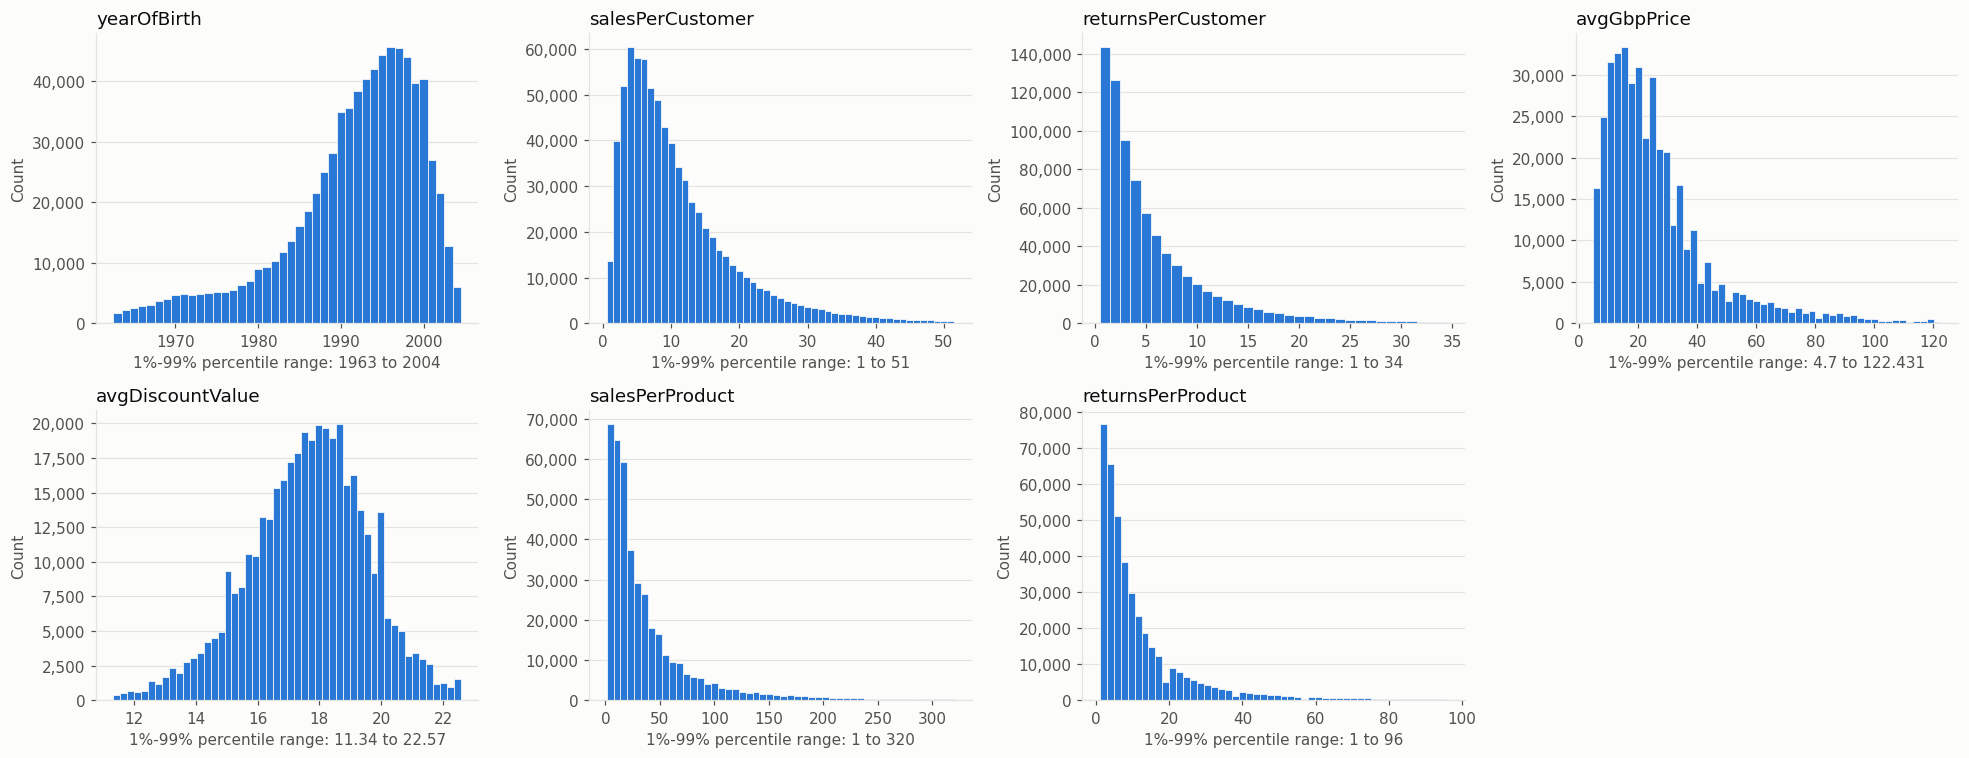

In [ ]:
numeric_features = {
    "yearOfBirth": customers["yearOfBirth"].mask(customers["yearOfBirth"] == PLACEHOLDER_BIRTH_YEAR).dropna(),
    "salesPerCustomer": customers["salesPerCustomer"],
    "returnsPerCustomer": customers["returnsPerCustomer"],
    "avgGbpPrice": products["avgGbpPrice"],
    "avgDiscountValue": products["avgDiscountValue"],
    "salesPerProduct": products["salesPerProduct"],
    "returnsPerProduct": products["returnsPerProduct"],
}

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, (name, values) in zip(axes.flat, numeric_features.items()):
    kept, cut_label = within_percentiles(values)
    distribution_hist(ax, kept, name, cut_label)
axes.flat[-1].set_visible(False)
fig.tight_layout()

Category shares: customers per country, share of male and premier customers, and variants per product type and brand.

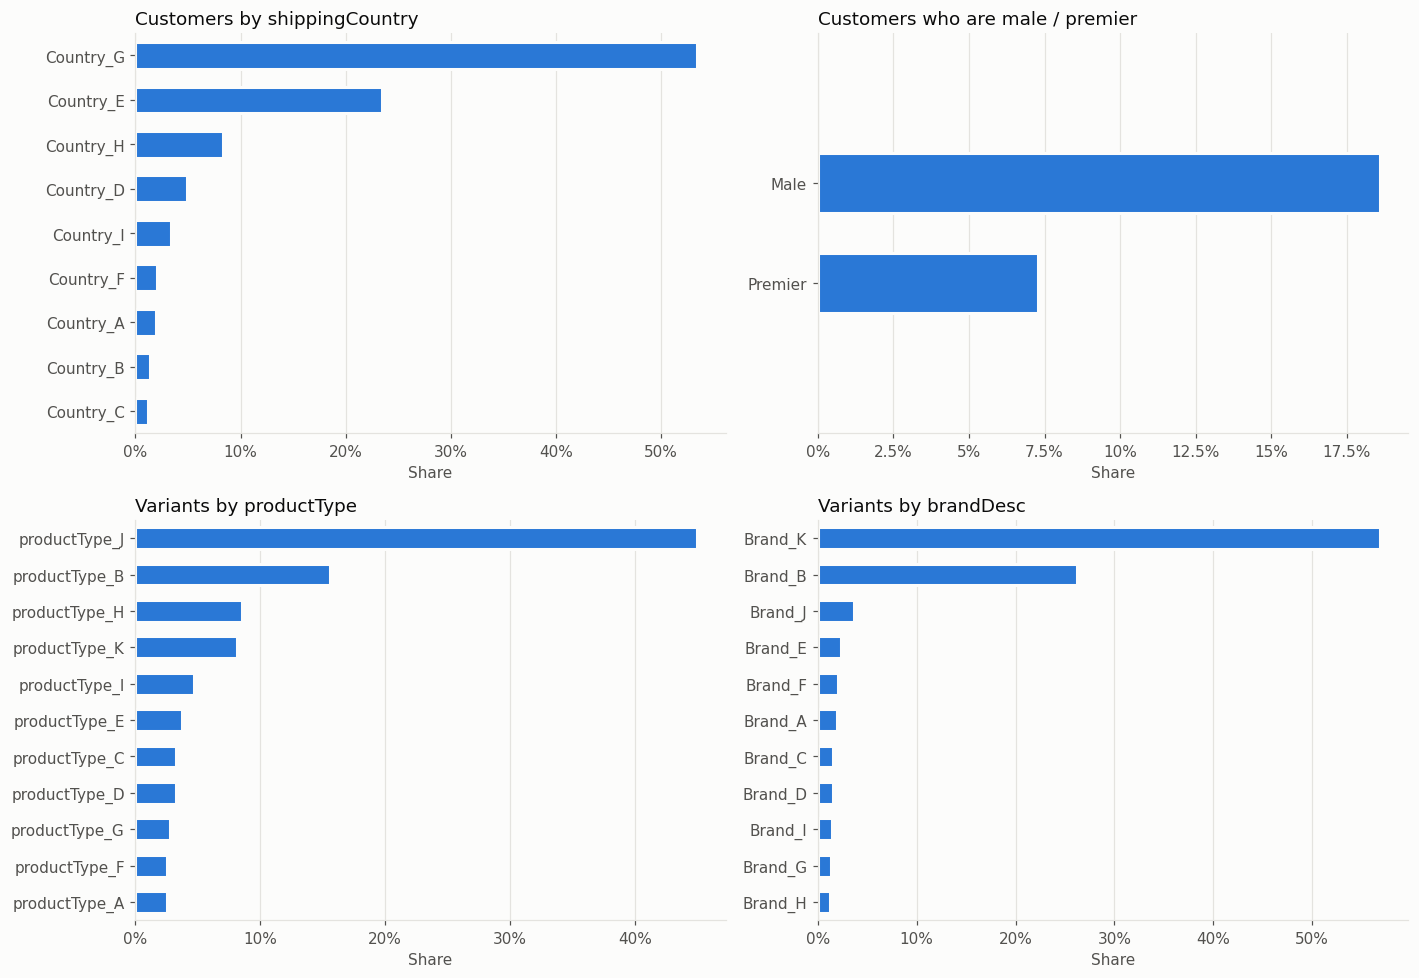

In [ ]:
category_shares = {
    "Customers by shippingCountry": customers["shippingCountry"].value_counts(normalize=True),
    "Customers who are male / premier": pd.Series(
        {"Male": customers["isMale"].mean(), "Premier": customers["premier"].mean()}),
    "Variants by productType": products["productType"].value_counts(normalize=True),
    "Variants by brandDesc": products["brandDesc"].value_counts(normalize=True),
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (title, shares) in zip(axes.flat, category_shares.items()):
    rate_barh(ax, shares.sort_values(), title, xlabel="Share")
fig.tight_layout()

Return reasons: share of all returns per reason code.
Each row's reason shares are weighted by its number of returns, once over customers and once over variants.
`D_2` is the second column named `..._return_code_D`; its real code is unknown.

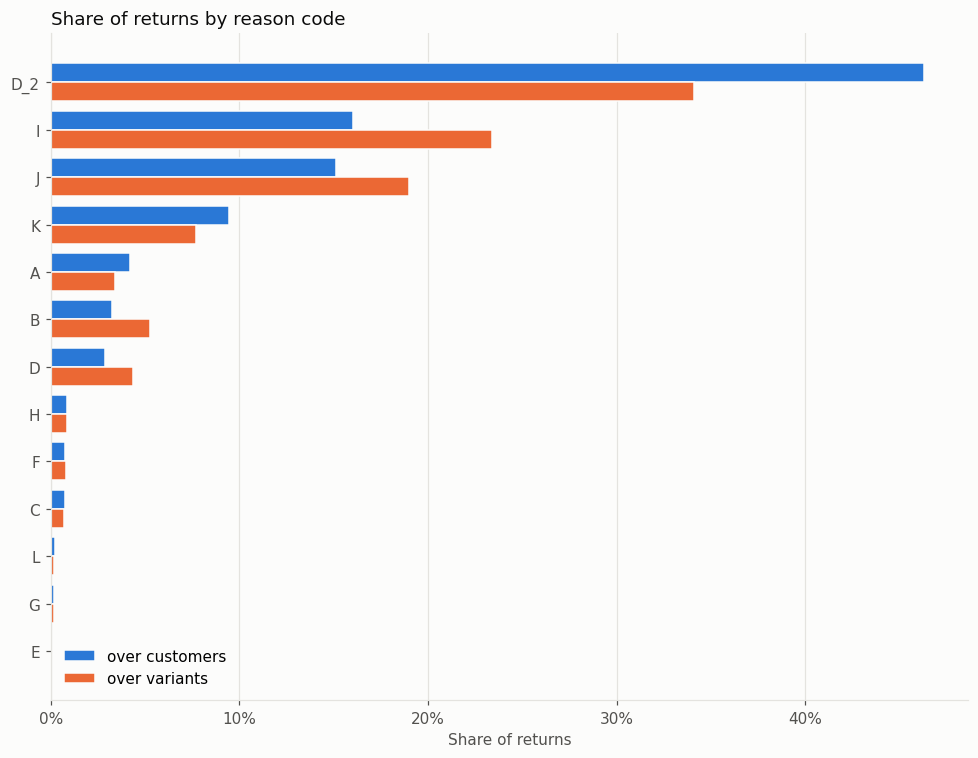

In [ ]:
def return_reason_shares(df: pd.DataFrame, prefix: str, returns_col: str):
    """Share of all returns per reason code, weighting each row's shares by its returns."""
    codes = dedupe_columns(df).filter(like=prefix)
    weighted = codes.mul(df[returns_col].to_numpy(), axis=0).sum()
    shares = weighted / weighted.sum()
    shares.index = shares.index.str.removeprefix(prefix)
    return shares


reason_shares = pd.DataFrame({
    "over customers": return_reason_shares(customers, "customerId_level_return_code_", "returnsPerCustomer"),
    "over variants": return_reason_shares(products, "variantID_level_return_code_", "returnsPerProduct"),
}).sort_values("over customers")

fig, ax = plt.subplots(figsize=(9, 7))
grouped_barh(ax, reason_shares, "Share of returns by reason code", "Share of returns")
fig.tight_layout()

### 4.4 Customer and product activity

How many events each customer and variant has in the training event table, and whether the return rate changes with activity.

,count,median events,share with 1 event
customers,810237.0,1.0,0.615
variants,432666.0,2.0,0.450


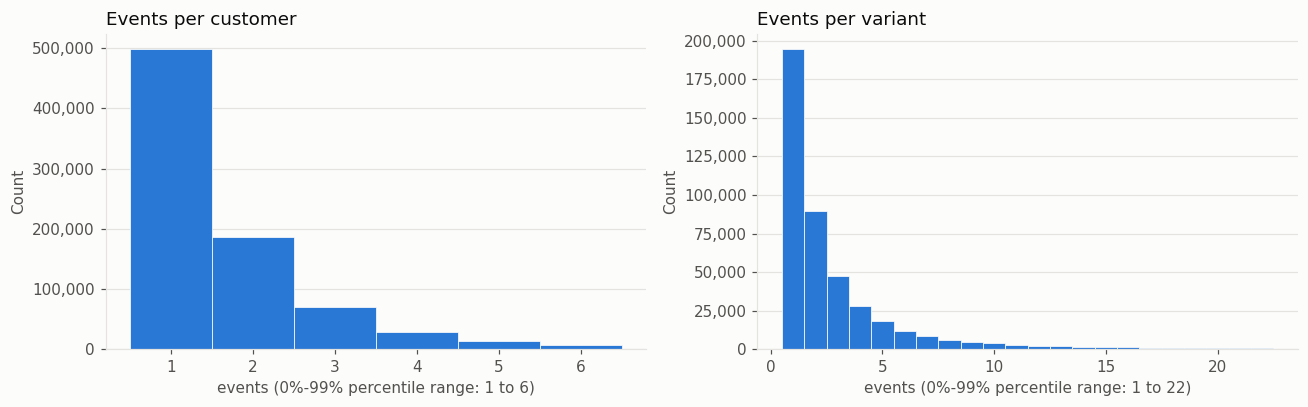

In [ ]:
events_per_customer = events.groupby("hash(customerId)").size()
events_per_variant = events.groupby("hash(variantID)").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (title, counts) in zip(axes, {"Events per customer": events_per_customer,
                                      "Events per variant": events_per_variant}.items()):
    kept, cut_label = within_percentiles(counts, lower=0.0)
    distribution_hist(ax, kept, title, f"events ({cut_label})")
fig.tight_layout()

pd.DataFrame({
    name: {"count": len(counts), "median events": counts.median(), "share with 1 event": round((counts == 1).mean(), 3)}
    for name, counts in {"customers": events_per_customer, "variants": events_per_variant}.items()
}).T

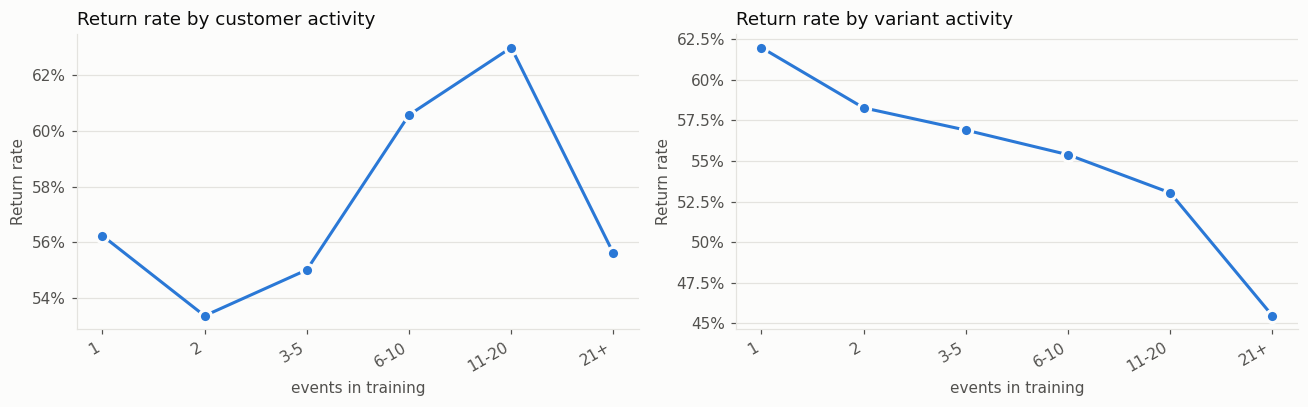

In [ ]:
ACTIVITY_BINS = [0, 1, 2, 5, 10, 20, float("inf")]
ACTIVITY_LABELS = ["1", "2", "3-5", "6-10", "11-20", "21+"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (key, counts, title) in zip(axes, [
    ("hash(customerId)", events_per_customer, "Return rate by customer activity"),
    ("hash(variantID)", events_per_variant, "Return rate by variant activity"),
]):
    activity_level = pd.cut(events[key].map(counts), bins=ACTIVITY_BINS, labels=ACTIVITY_LABELS)
    rate_line(ax, events.groupby(activity_level, observed=True)["isReturned"].mean(), title,
              "events in training")
fig.tight_layout()

### 4.5 Return rates from node totals

Rates from the customer and product totals, pooled as total returns / total sales per group, so big customers and products weigh more.
These totals come from a wider history than the event table, so their overall rates differ from the event return rate.

#### Return rate distributions

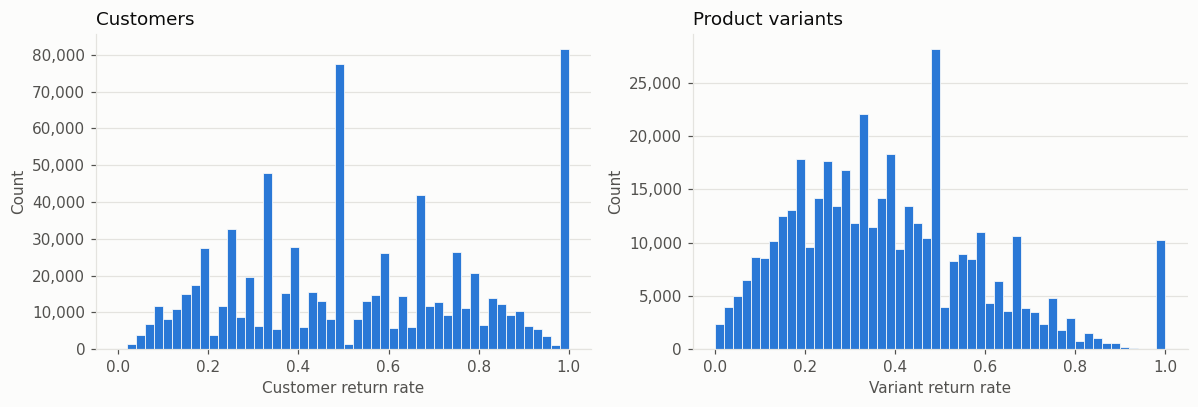

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
distribution_hist(axes[0], customers["customerReturnRate"], "Customers", "Customer return rate")
distribution_hist(axes[1], products["productReturnRate"], "Product variants", "Variant return rate")
fig.tight_layout()

#### Return rate by category

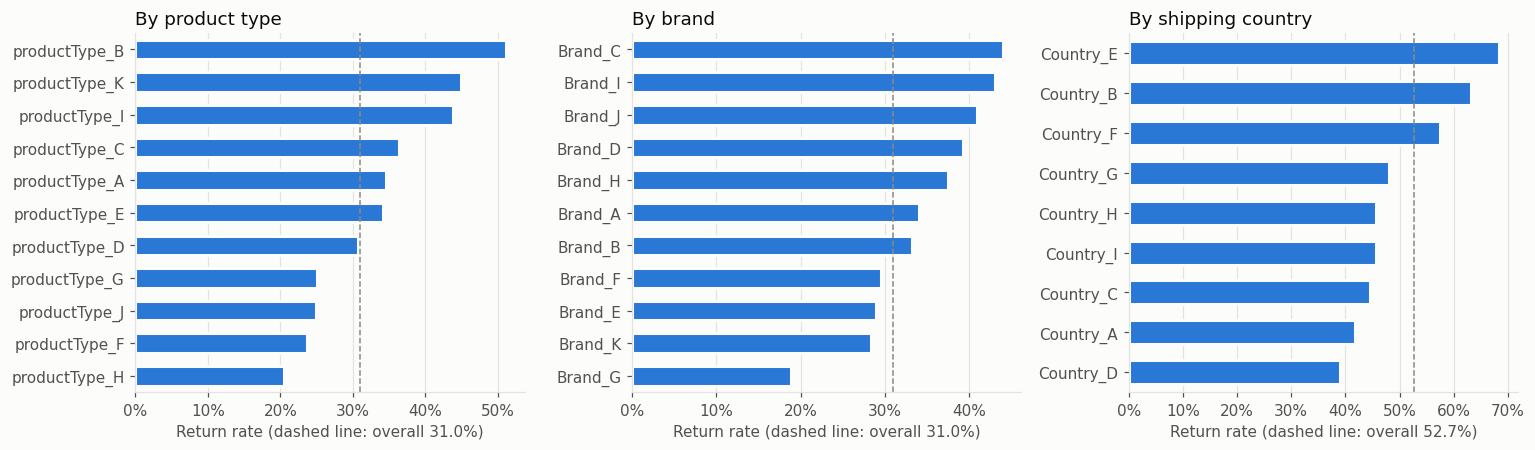

In [ ]:
product_overall = overall_return_rate(products, "salesPerProduct", "returnsPerProduct")
customer_overall = overall_return_rate(customers, "salesPerCustomer", "returnsPerCustomer")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
rate_barh(
    axes[0],
    return_rate_by(products, "productType", "salesPerProduct", "returnsPerProduct"),
    "By product type",
    product_overall,
)
rate_barh(
    axes[1],
    return_rate_by(products, "brandDesc", "salesPerProduct", "returnsPerProduct"),
    "By brand",
    product_overall,
)
rate_barh(
    axes[2],
    return_rate_by(customers, "shippingCountry", "salesPerCustomer", "returnsPerCustomer"),
    "By shipping country",
    customer_overall,
)
fig.tight_layout()

#### Return rate by price

Variants split into 10 equal-size price bins.

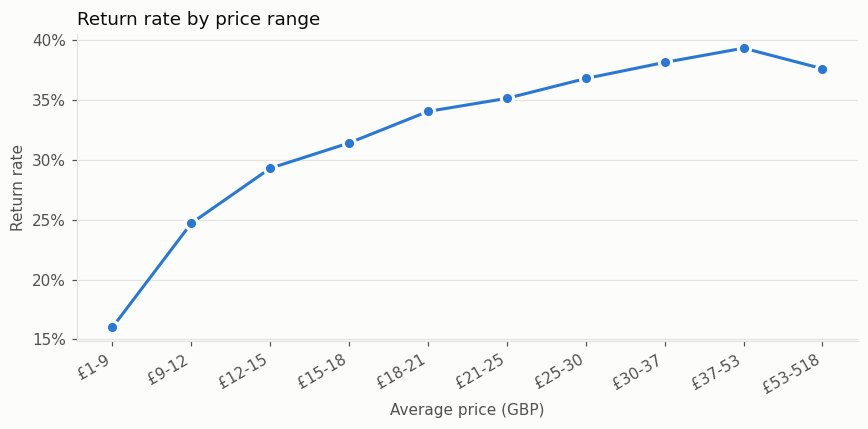

In [ ]:
price_bins = pd.qcut(products["avgGbpPrice"], q=10)
price_bins = price_bins.cat.rename_categories(
    lambda interval: f"£{interval.left:.0f}-{interval.right:.0f}"
)

fig, ax = plt.subplots(figsize=(8, 4))
rate_line(
    ax,
    return_rate_by(products, price_bins, "salesPerProduct", "returnsPerProduct").sort_index(),
    "Return rate by price range",
    "Average price (GBP)",
)
fig.tight_layout()

### 4.6 Return rates per event

Rates and feature distributions per purchase event, from the flattened training data.

#### Return rate by categorical feature

Share of events returned per category. Events with no matching node row are left out of that feature's bars.

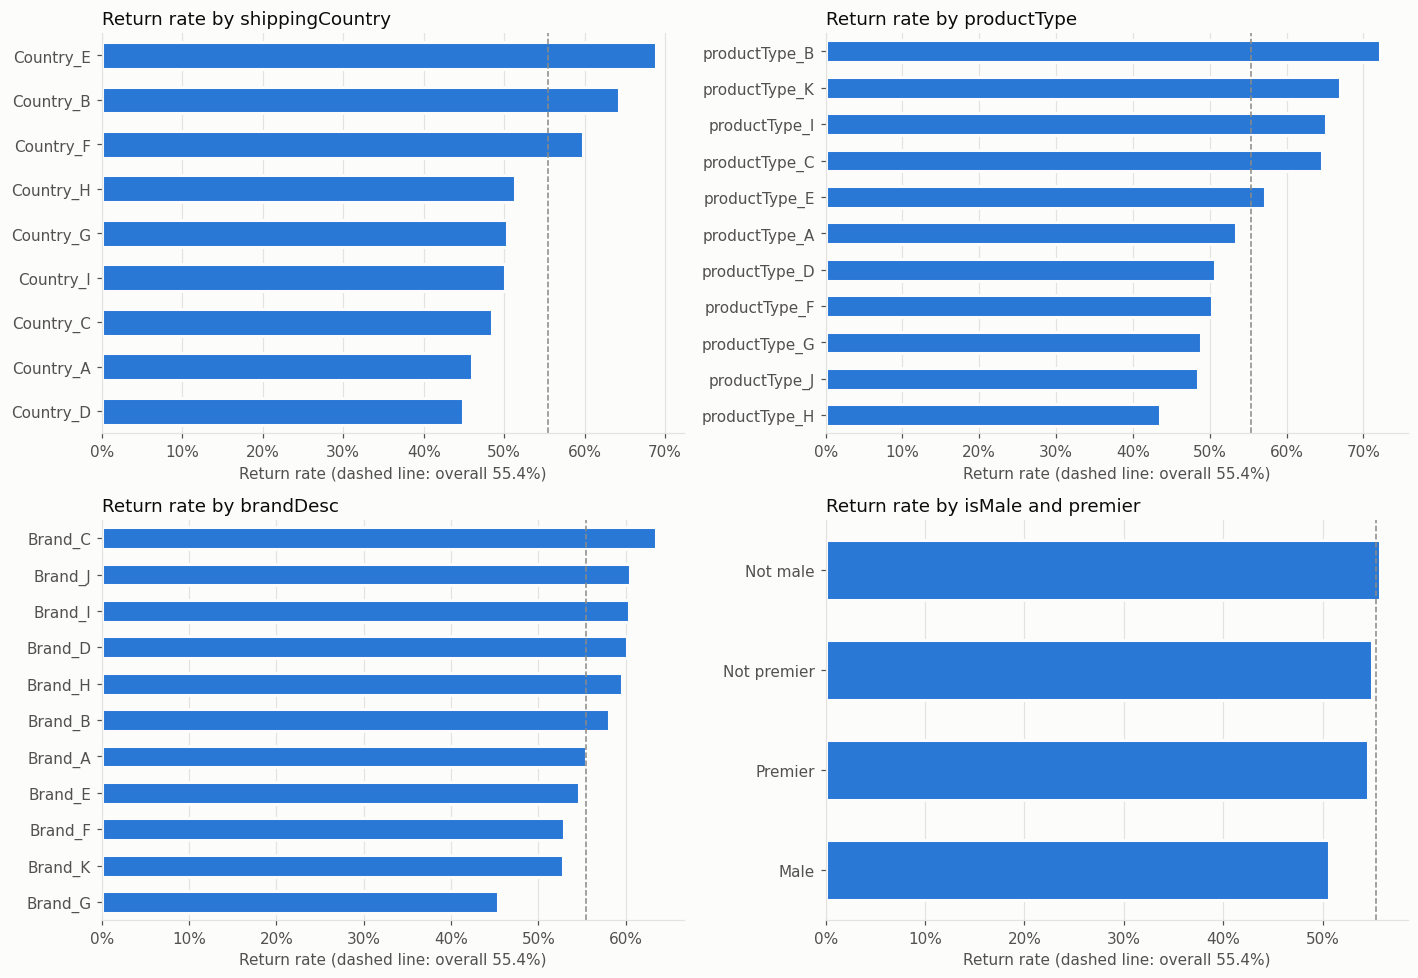

In [ ]:
cat_cols = ["shippingCountry", "productType", "brandDesc"]
flag_labels = {
    "isMale": {0: "Not male", 1: "Male"},
    "premier": {0: "Not premier", 1: "Premier"},
}

flag_rates = pd.concat([
    event_df.groupby(event_df[col].map(names))["isReturned"].mean()
    for col, names in flag_labels.items()
]).sort_values()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, cat_cols):
    rates = event_df.groupby(col)["isReturned"].mean().sort_values()
    rate_barh(ax, rates, f"Return rate by {col}", overall)
rate_barh(axes.flat[-1], flag_rates, "Return rate by isMale and premier", overall)
fig.tight_layout()

#### Numeric features by class

Box plots without outliers, then density curves on a 100,000 event sample, cut to the 1st-99th percentile range so long tails do not flatten the curves.

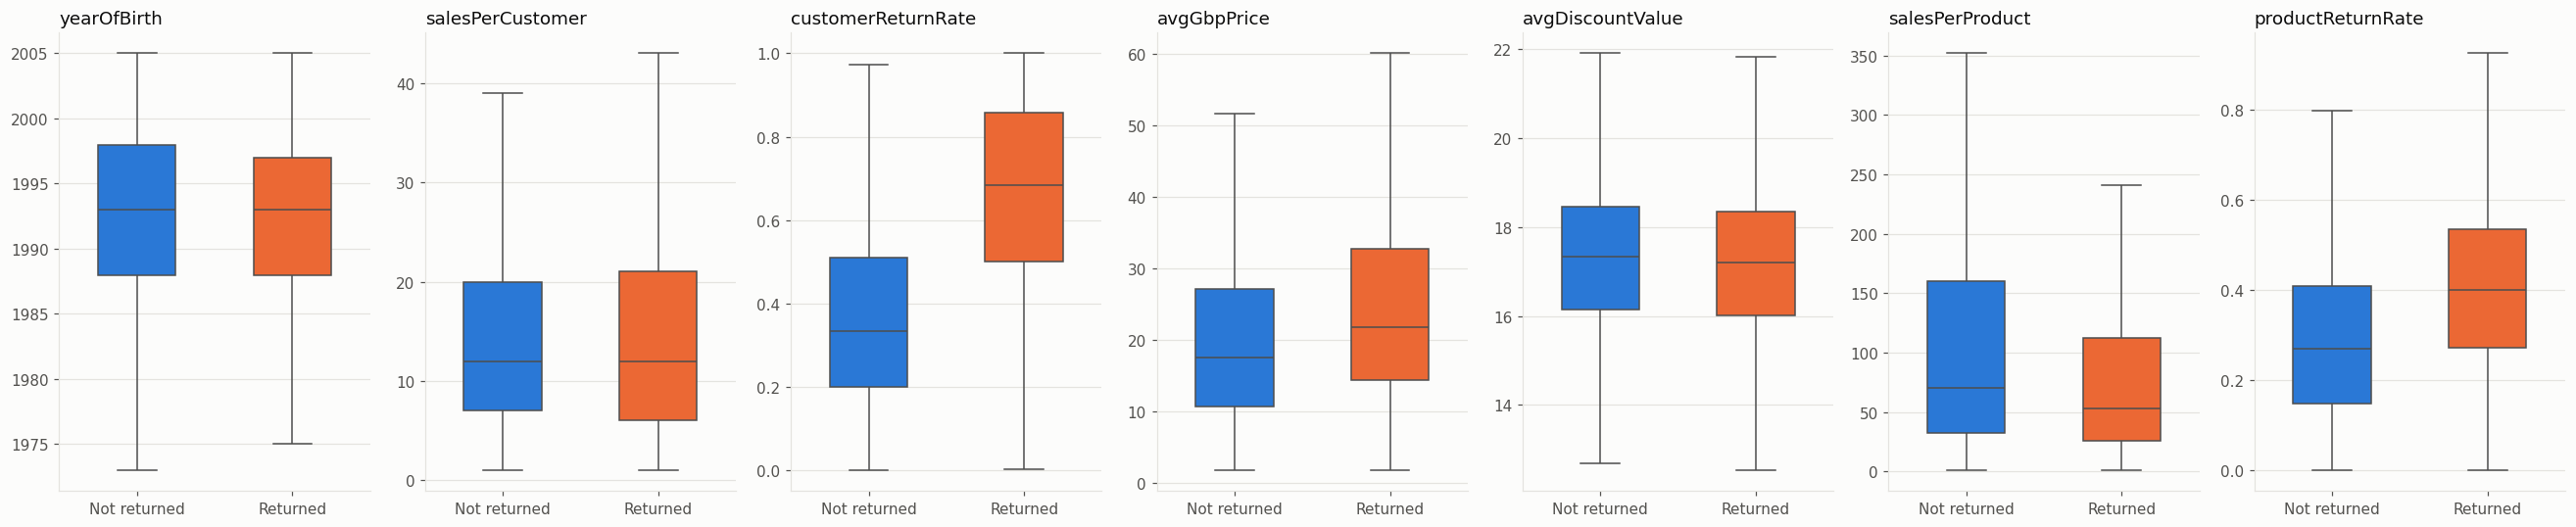

In [ ]:
num_cols = [
    "yearOfBirth", "salesPerCustomer", "customerReturnRate",
    "avgGbpPrice", "avgDiscountValue", "salesPerProduct", "productReturnRate",
]
class_names = event_df["isReturned"].map(CLASS_LABELS)
class_palette = {CLASS_LABELS[k]: v for k, v in CLASS_COLORS.items()}

fig, axes = plt.subplots(1, len(num_cols), figsize=(24, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=class_names, y=event_df[col], hue=class_names, palette=class_palette,
                showfliers=False, width=0.5, saturation=1, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.tight_layout()

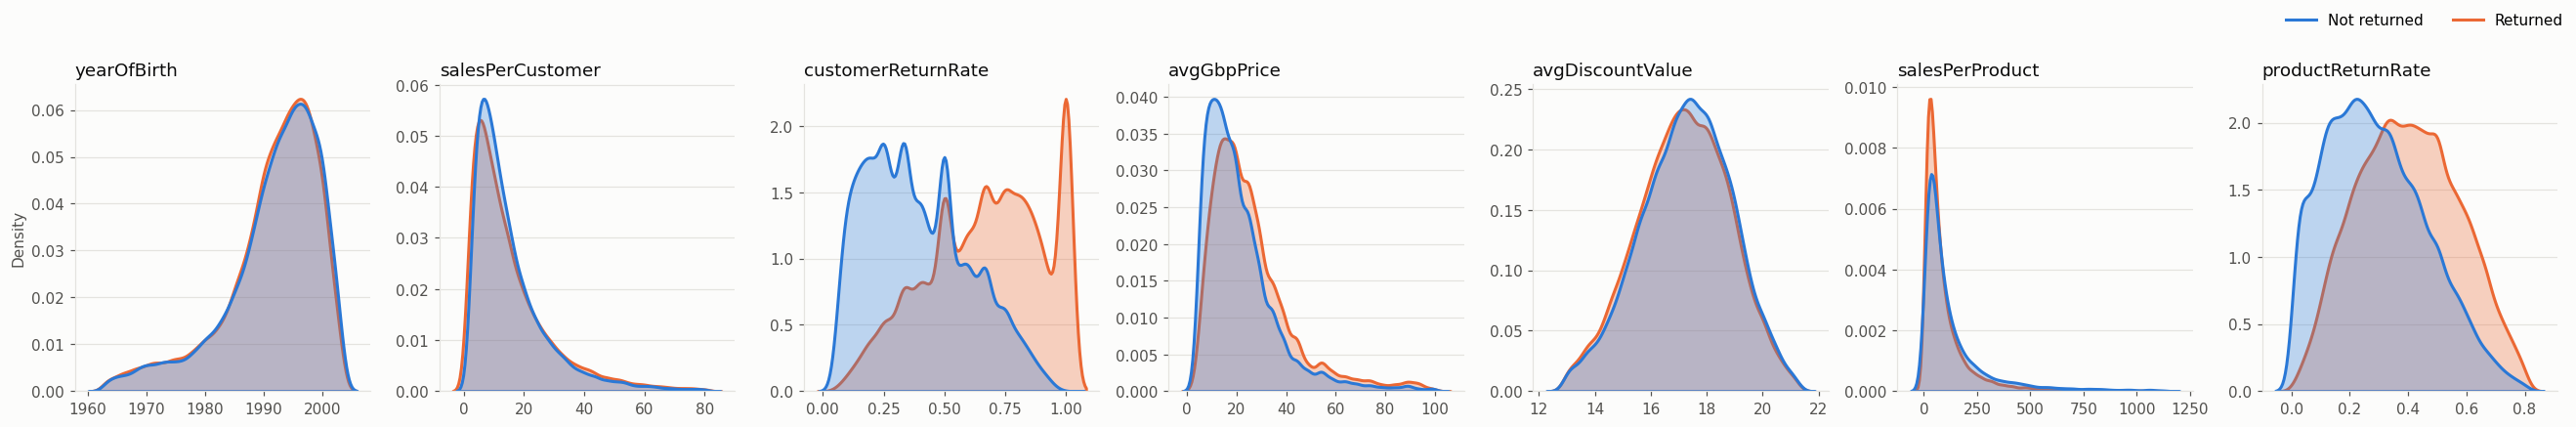

In [ ]:
kde_sample = event_df.sample(100_000, random_state=42)
kde_classes = kde_sample["isReturned"].map(CLASS_LABELS)

fig, axes = plt.subplots(1, len(num_cols), figsize=(24, 4))
for ax, col in zip(axes, num_cols):
    lower, upper = kde_sample[col].quantile([0.01, 0.99])
    values = kde_sample[col].where(kde_sample[col].between(lower, upper))
    sns.kdeplot(x=values, hue=kde_classes, hue_order=list(CLASS_LABELS.values()), palette=class_palette,
                common_norm=False, fill=True, alpha=0.3, linewidth=2, legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Density")
fig.legend(
    handles=[plt.Line2D([], [], color=CLASS_COLORS[k], linewidth=2, label=v) for k, v in CLASS_LABELS.items()],
    loc="upper right", ncols=2, frameon=False,
)
fig.tight_layout(rect=(0, 0, 1, 0.9))

In [ ]:
event_df.groupby("isReturned")[num_cols].median().T.rename(columns=CLASS_LABELS)

isReturned,Not returned,Returned
yearOfBirth,1993.000000,1993.000000
salesPerCustomer,12.000000,12.000000
customerReturnRate,0.333333,0.684211
avgGbpPrice,17.560000,21.730000
avgDiscountValue,17.340000,17.210000
salesPerProduct,70.000000,53.000000
productReturnRate,0.270492,0.400000


### 4.7 Training vs testing

Whether the testing split looks like training.
Large differences would make training scores a poor guide to testing.
The standardised mean difference is (testing mean - training mean) / training standard deviation; values near 0 mean little shift.

In [ ]:
shift_cols = ["yearOfBirth", "salesPerCustomer", "customerReturnRate",
              "avgGbpPrice", "avgDiscountValue", "salesPerProduct", "productReturnRate"]
train_values, test_values = flat["training"][shift_cols], flat["testing"][shift_cols]

pd.DataFrame({
    "training median": train_values.median(),
    "testing median": test_values.median(),
    "standardised mean difference": (test_values.mean() - train_values.mean()) / train_values.std(),
}).round(3)

,training median,testing median,standardised mean difference
yearOfBirth,1993.000,1993.000,-0.003
salesPerCustomer,12.000,12.000,0.008
customerReturnRate,0.513,0.500,-0.032
avgGbpPrice,19.690,20.000,0.049
avgDiscountValue,17.270,17.430,0.063
salesPerProduct,60.000,75.000,0.078
productReturnRate,0.343,0.346,0.004


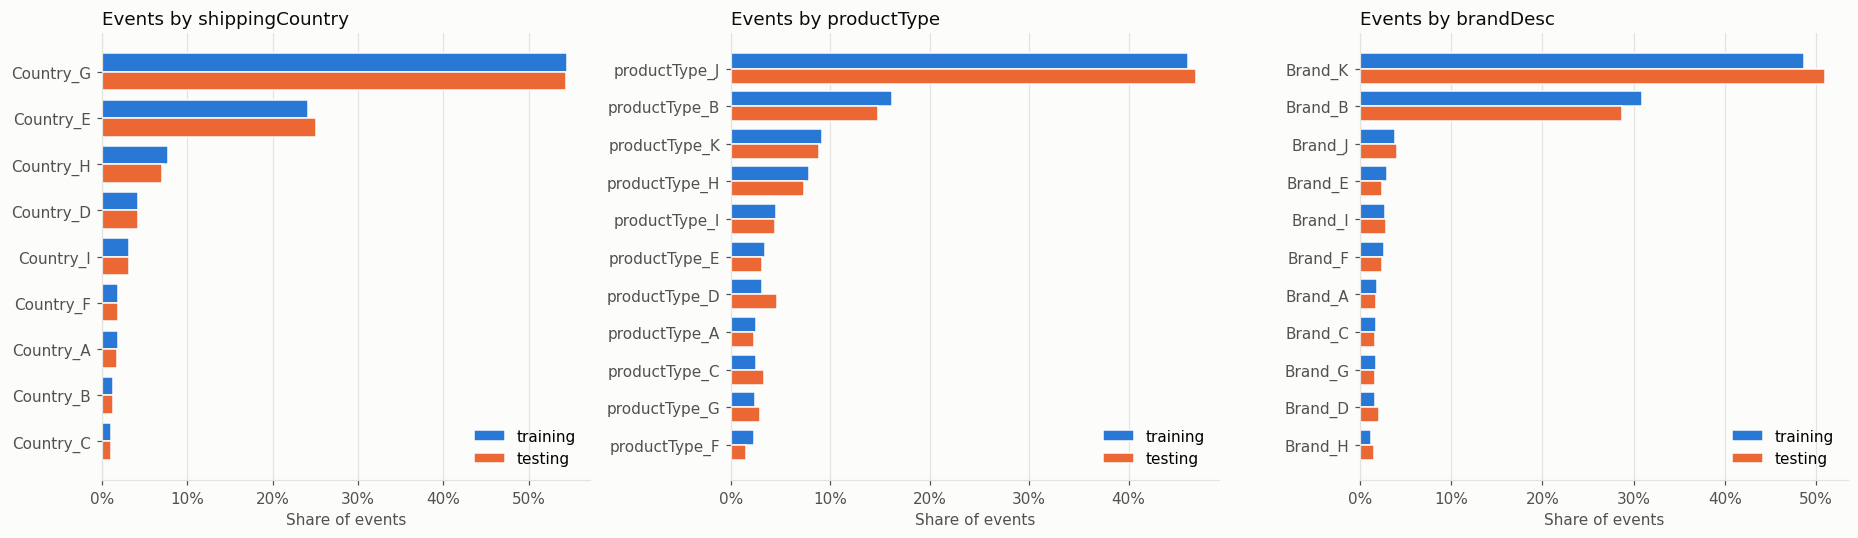

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, cat_cols):
    shares = pd.DataFrame({split: df[col].value_counts(normalize=True) for split, df in flat.items()})
    grouped_barh(ax, shares.sort_values("training"), f"Events by {col}", "Share of events")
fig.tight_layout()

### 4.8 Missing values

Missing values in the flattened data (both splits), where they come from, and whether they differ between returned and kept events.

The raw tables have no missing values, so every missing value in the flattened data comes from the join or from the birth year placeholder.

In [ ]:
pd.Series({f"{name} ({split})": int(df.isna().sum().sum()) for (name, split), df in tables.items()}, name="missing values")

,missing values
customer_nodes (training),0
customer_nodes (testing),0
product_nodes (training),0
product_nodes (testing),0
event_table (training),0
event_table (testing),0


#### Rows with missing values

In [ ]:
row_summary = pd.DataFrame({
    split: {
        "Rows": len(df),
        "Rows with any missing value": int(df.isna().any(axis=1).sum()),
        "Complete rows": int(df.notna().all(axis=1).sum()),
    }
    for split, df in flat.items()
}).T
row_summary["% with any missing value"] = (
    row_summary["Rows with any missing value"] / row_summary["Rows"] * 100
).round(1)
row_summary

,Rows,Rows with any missing value,Complete rows,% with any missing value
training,1362582,532025,830557,39.0
testing,1453143,513440,939703,35.3


#### Missing values per column

Only columns with at least one missing value. `source` is the table the column comes from.

In [ ]:
customer_columns = set(dedupe_columns(customers).columns)
row_counts = pd.Series({split: len(df) for split, df in flat.items()})

missing_counts = pd.DataFrame({split: df.isna().sum() for split, df in flat.items()})
missing_counts = missing_counts[missing_counts.sum(axis=1) > 0]

missing_by_column = pd.concat(
    {"missing rows": missing_counts, "% missing": missing_counts.div(row_counts).mul(100).round(2)},
    axis=1,
)
missing_by_column.insert(
    0, ("source", ""), ["customer_nodes" if col in customer_columns else "product_nodes" for col in missing_by_column.index]
)
missing_by_column

source missing rows          \
                                                     training testing   
yearOfBirth                       customer_nodes        92545   98087   
isMale                            customer_nodes        71197   74559   
shippingCountry                   customer_nodes        71197   74559   
premier                           customer_nodes        71197   74559   
salesPerCustomer                  customer_nodes        71197   74559   
returnsPerCustomer                customer_nodes        71197   74559   
customerReturnRate                customer_nodes        71197   74559   
customerId_level_return_code_A    customer_nodes        71197   74559   
customerId_level_return_code_B    customer_nodes        71197   74559   
customerId_level_return_code_C    customer_nodes        71197   74559   
customerId_level_return_code_D    customer_nodes        71197   74559   
customerId_level_return_code_E    customer_nodes        71197   74559   
customerId_level_return_code_D_2  customer_nodes        71197   74559   
customerId_level_return_code_F    customer_nodes        71197   74559   
customerId_level_return_code_G    customer_nodes        71197   74559   
customerId_level_return_code_H    customer_nodes        71197   74559   
customerId_level_return_code_I    customer_nodes        71197   74559   
customerId_level_return_code_J    customer_nodes        71197   74559   
customerId_level_return_code_K    customer_nodes        71197   74559   
customerId_level_return_code_L    customer_nodes        71197   74559   
hash(productID)                    product_nodes       472355  449805   
productType                        product_nodes       472355  449805   
hash(supplierRef)                  product_nodes       472355  449805   
brandDesc                          product_nodes       472355  449805   
avgGbpPrice                        product_nodes       472355  449805   
avgDiscountValue                   product_nodes       472355  449805   
salesPerProduct                    product_nodes       472355  449805   
returnsPerProduct                  product_nodes       472355  449805   
productReturnRate                  product_nodes       472355  449805   
variantID_level_return_code_A      product_nodes       472355  449805   
variantID_level_return_code_B      product_nodes       472355  449805   
variantID_level_return_code_C      product_nodes       472355  449805   
variantID_level_return_code_D      product_nodes       472355  449805   
variantID_level_return_code_E      product_nodes       472355  449805   
variantID_level_return_code_D_2    product_nodes       472355  449805   
variantID_level_return_code_F      product_nodes       472355  449805   
variantID_level_return_code_G      product_nodes       472355  449805   
variantID_level_return_code_H      product_nodes       472355  449805   
variantID_level_return_code_I      product_nodes       472355  449805   
variantID_level_return_code_J      product_nodes       472355  449805   
variantID_level_return_code_K      product_nodes       472355  449805   
variantID_level_return_code_L      product_nodes       472355  449805   

                                 % missing          
                                  training testing  
yearOfBirth                           6.79    6.75  
isMale                                5.23    5.13  
shippingCountry                       5.23    5.13  
premier                               5.23    5.13  
salesPerCustomer                      5.23    5.13  
returnsPerCustomer                    5.23    5.13  
customerReturnRate                    5.23    5.13  
customerId_level_return_code_A        5.23    5.13  
customerId_level_return_code_B        5.23    5.13  
customerId_level_return_code_C        5.23    5.13  
customerId_level_return_code_D        5.23    5.13  
customerId_level_return_code_E        5.23    5.13  
customerId_level_return_code_D_2      5.23    5.13  
customerId_level_return_code_F    

#### Why rows are missing values

Each row can have up to three causes:
- **No customer row**: the event's `hash(customerId)` is not in `customer_nodes`, so every customer feature is missing.
- **No product row**: the event's `hash(variantID)` is not in `product_nodes`, so every product feature is missing.
- **Birth year placeholder**: the customer exists but `yearOfBirth` was 1900, so only that column is missing.

In [ ]:
def missing_causes(df: pd.DataFrame):
    """One boolean column per cause of missing values, for each row."""
    no_customer = df["isMale"].isna()
    return pd.DataFrame({
        "No customer row": no_customer,
        "No product row": df["avgGbpPrice"].isna(),
        "Birth year placeholder": ~no_customer & df["yearOfBirth"].isna(),
    })


def cause_pattern_counts(df: pd.DataFrame):
    """Number of rows per combination of causes, labelled like "No customer row + No product row"."""
    causes = missing_causes(df)
    counts = causes.value_counts()
    counts.index = [
        " + ".join(name for name, flag in zip(causes.columns, flags) if flag) or "Complete"
        for flags in counts.index
    ]
    return counts


pattern_counts = pd.DataFrame({split: cause_pattern_counts(df) for split, df in flat.items()}).fillna(0).astype(int)
pattern_counts = pattern_counts.sort_values("training", ascending=False)
pattern_share = pattern_counts.div(row_counts).mul(100)

pd.concat({"rows": pattern_counts, "% of rows": pattern_share.round(2)}, axis=1)

rows         % of rows        
                                        training testing  training testing
Complete                                  830557  939703     60.95   64.67
No product row                            439480  415353     32.25   28.58
No customer row                            45822   47546      3.36    3.27
No customer row + No product row           25375   27013      1.86    1.86
Birth year placeholder                     13848   16089      1.02    1.11
No product row + Birth year placeholder     7500    7439      0.55    0.51

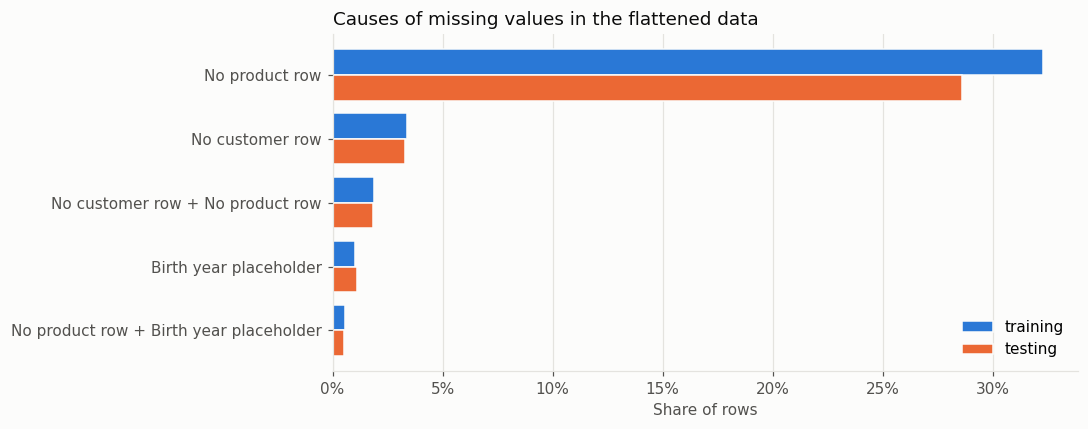

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
grouped_barh(ax, pattern_share.drop(index="Complete").iloc[::-1] / 100,
             "Causes of missing values in the flattened data", "Share of rows")
fig.tight_layout()

#### Missing features by class

Share of events whose customer or variant has no row in the node tables, so all of its features are missing.

isReturned                      Not returned  Returned
Customer not in customer_nodes           4.1       6.1
Variant not in product_nodes            34.5      34.8


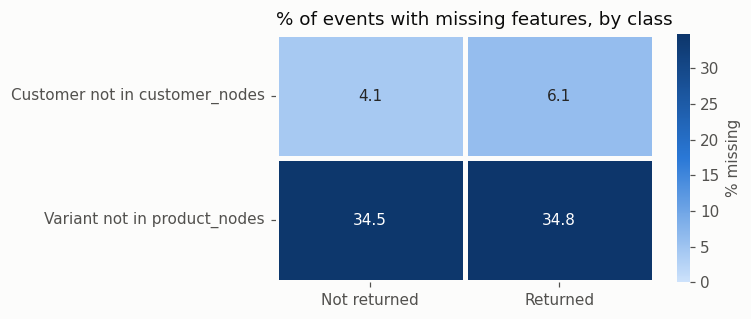

In [ ]:
missing = (
    event_df.groupby("isReturned")[["isMale", "avgGbpPrice"]]
    .apply(lambda g: g.isna().mean() * 100)
    .T.rename(
        index={"isMale": "Customer not in customer_nodes", "avgGbpPrice": "Variant not in product_nodes"},
        columns=CLASS_LABELS,
    )
)
print(missing.round(1))

fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(missing, annot=True, fmt=".1f", cmap=SEQUENTIAL_CMAP, vmin=0, linewidths=2,
            linecolor=SURFACE, cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("% of events with missing features, by class")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()

### 4.9 Feature relationships

How the features relate to each other and to the target.

#### 2D projection

PCA on the standardised numeric features, for a random sample of 20,000 events with all features present.

Points are drawn in random (sample) order, so neither class is painted over the other.

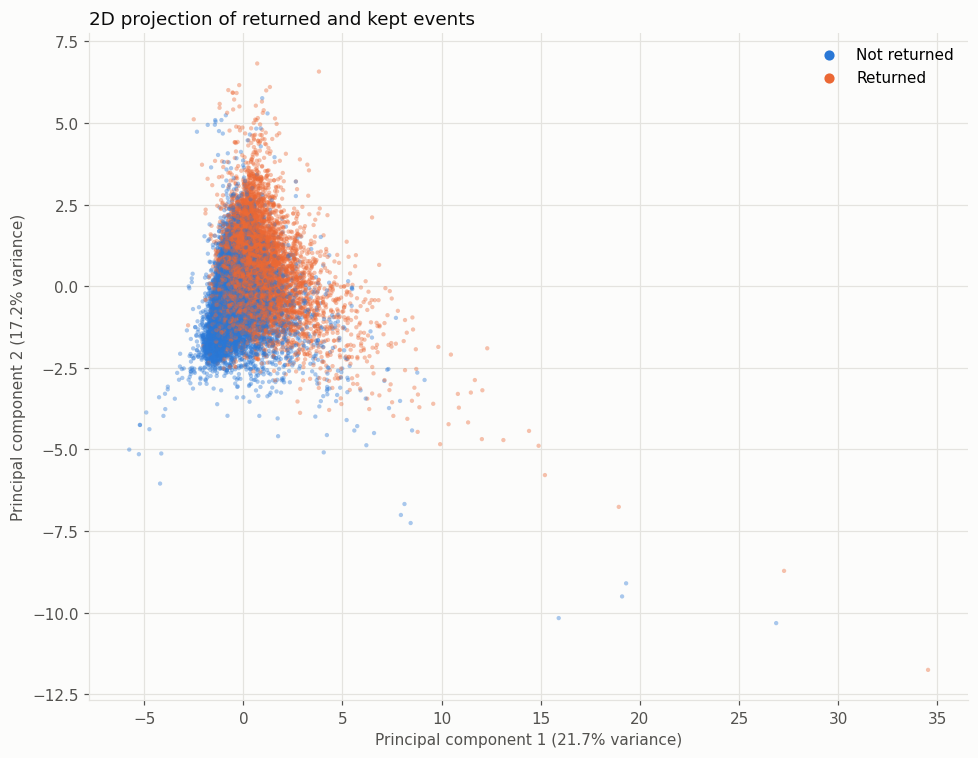

In [ ]:
pca_cols = [
    "yearOfBirth", "salesPerCustomer", "returnsPerCustomer", "customerReturnRate",
    "avgGbpPrice", "avgDiscountValue", "salesPerProduct", "returnsPerProduct", "productReturnRate",
]
pca_sample = event_df[pca_cols + ["isReturned"]].dropna().sample(20_000, random_state=42)

pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(StandardScaler().fit_transform(pca_sample[pca_cols]))

labels = pca_sample["isReturned"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(components[:, 0], components[:, 1], s=8, alpha=0.4, linewidths=0,
           c=[CLASS_COLORS[label] for label in labels])
for label in (0, 1):
    ax.scatter([], [], s=8, color=CLASS_COLORS[label], label=CLASS_LABELS[label])
ax.set_xlabel(f"Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("2D projection of returned and kept events")
ax.legend(markerscale=2, frameon=False)
fig.tight_layout()

#### Predictive power

ROC-AUC of each feature used alone as a score.
Missing numbers become -1, missing categories become `MISSING`, and categories are scored by their return rate on this same data, so their AUC is slightly optimistic.
A feature far above 0.5 on its own deserves a leakage check before it goes into a model.

In [ ]:
def single_feature_auc(values: pd.Series, target: pd.Series):
    """ROC-AUC of one feature used alone, flipped so it is always >= 0.5."""
    if values.dtype.kind in "iufb":
        score = values.fillna(-1)
    else:
        filled = values.fillna("MISSING")
        score = filled.map(target.groupby(filled).mean())
    auc = roc_auc_score(target, score)
    return max(auc, 1 - auc)


auc_cols = [
    col for col in event_df.columns
    if col not in ("isReturned", "hash(variantID)", "hash(customerId)", "hash(productID)", "hash(supplierRef)")
]
auc = pd.Series({col: single_feature_auc(event_df[col], event_df["isReturned"]) for col in auc_cols}).sort_values()
print(auc.round(3).to_string())

variantID_level_return_code_B       0.500
variantID_level_return_code_E       0.501
customerId_level_return_code_J      0.502
customerId_level_return_code_B      0.502
variantID_level_return_code_D       0.503
variantID_level_return_code_F       0.503
variantID_level_return_code_H       0.503
customerId_level_return_code_H      0.504
variantID_level_return_code_A       0.504
variantID_level_return_code_C       0.505
variantID_level_return_code_G       0.505
customerId_level_return_code_I      0.505
customerId_level_return_code_A      0.506
customerId_level_return_code_C      0.506
variantID_level_return_code_L       0.506
customerId_level_return_code_L      0.506
customerId_level_return_code_F      0.507
customerId_level_return_code_D      0.508
customerId_level_return_code_G      0.509
avgDiscountValue                    0.509
customerId_level_return_code_E      0.510
premier                             0.510
variantID_level_return_code_D_2     0.516
variantID_level_return_code_I     

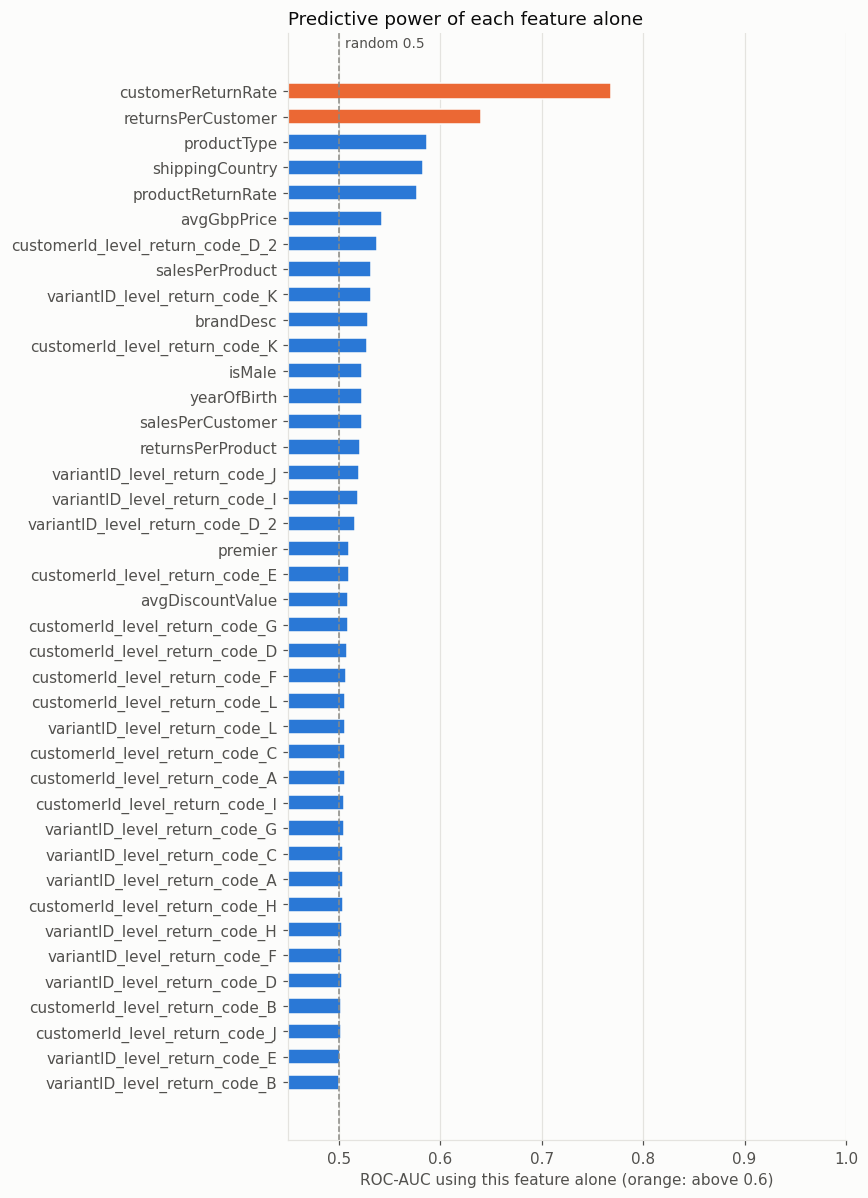

In [ ]:
fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(auc.index, auc.values, height=0.6, edgecolor=SURFACE, linewidth=1,
        color=[SERIES[1] if v > 0.6 else SERIES[0] for v in auc.values])
ax.axvline(0.5, color=REFERENCE, linestyle="--", linewidth=1)
ax.annotate("random 0.5", xy=(0.5, 1), xycoords=("data", "axes fraction"), xytext=(4, -2),
            textcoords="offset points", va="top", color=TEXT_SECONDARY, fontsize=9)
ax.set_xlim(0.45, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC using this feature alone (orange: above 0.6)")
ax.set_title("Predictive power of each feature alone")
fig.tight_layout()

#### Correlation with the target

Correlation matrix of the 25 features most correlated with `isReturned`, with the categorical features one-hot encoded from their string columns.

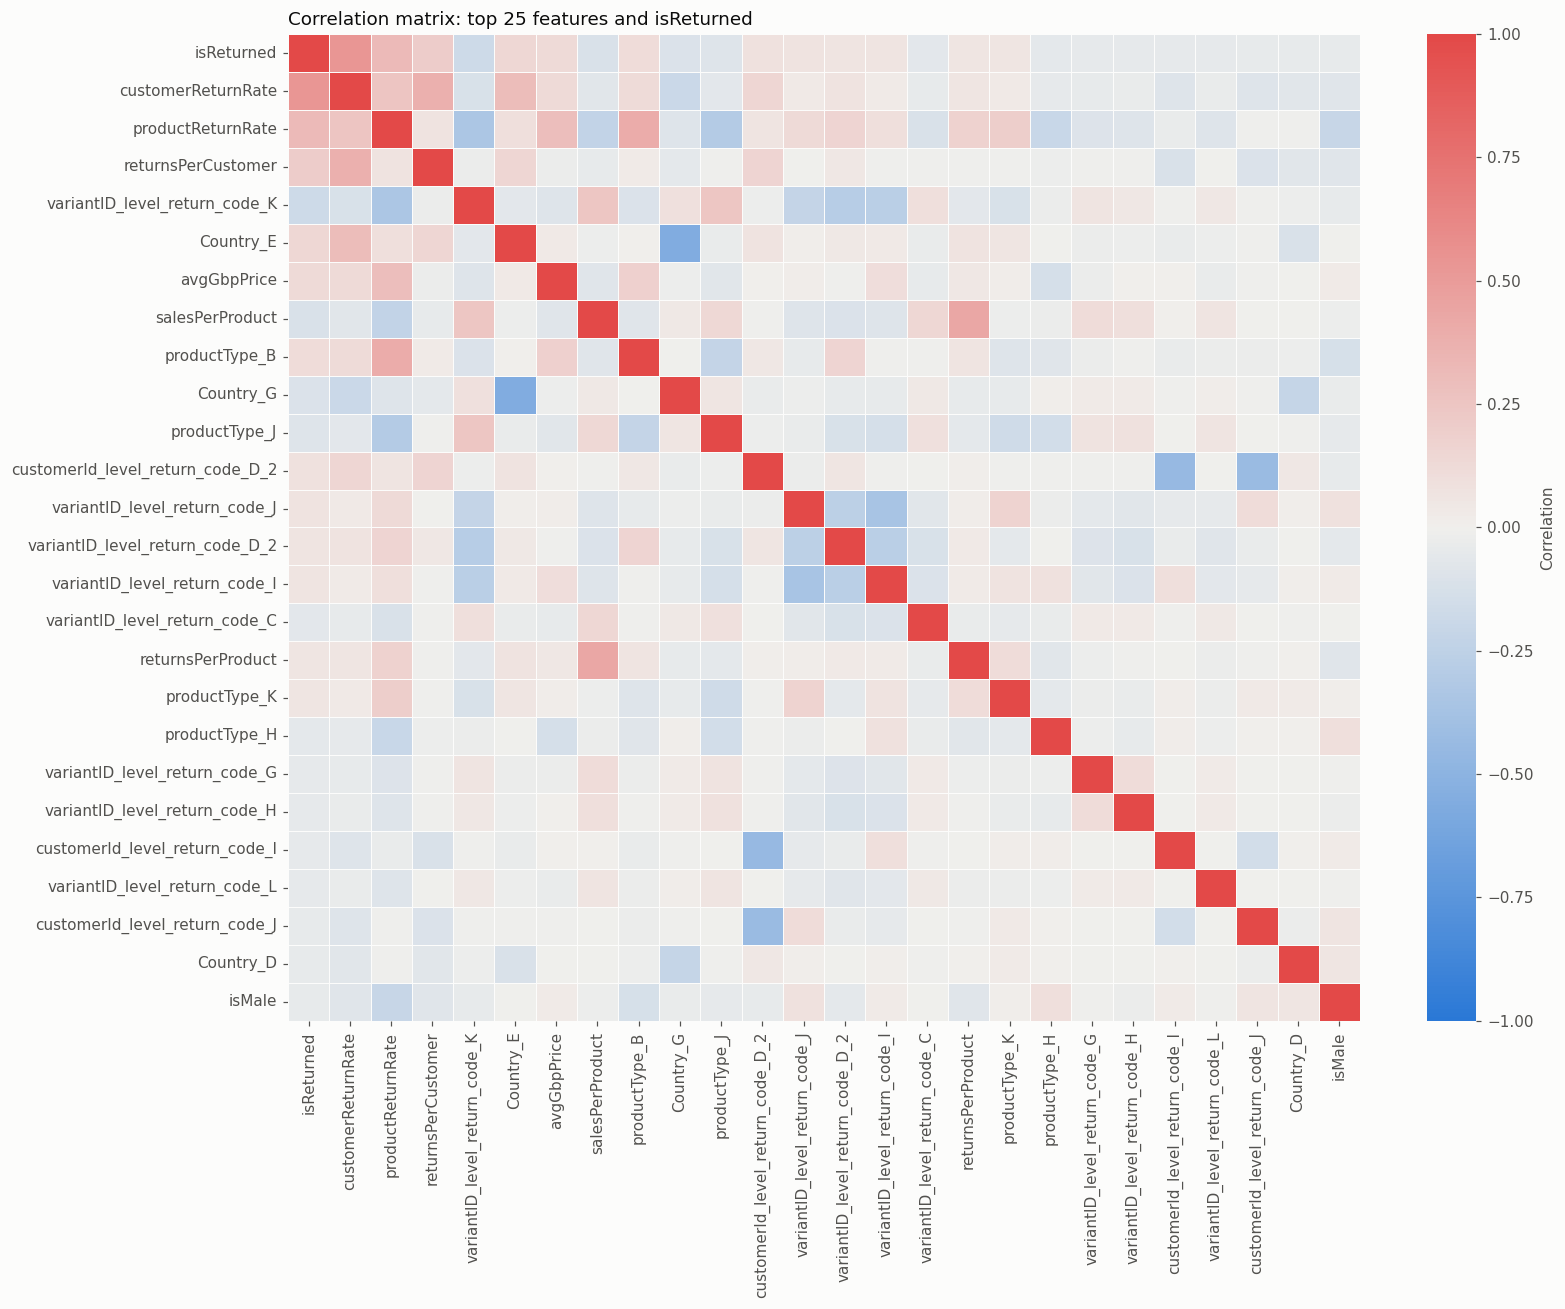

In [ ]:
corr = pd.get_dummies(
    event_df.drop(columns=["hash(variantID)", "hash(customerId)", "hash(productID)", "hash(supplierRef)"]),
    columns=["shippingCountry", "productType", "brandDesc"],
    prefix="",
    prefix_sep="",
    dtype="uint8",
).corr()
top_features = corr["isReturned"].drop("isReturned").abs().nlargest(25).index.tolist()
heatmap_cols = ["isReturned"] + top_features

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr.loc[heatmap_cols, heatmap_cols], cmap=DIVERGING_CMAP, center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor=SURFACE, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation matrix: top 25 features and isReturned")
fig.tight_layout()

### 4.10 Hypothesis tests
**Tests 1–3 (chi-square):** H0: return status is independent of shipping country (Test 1), product type (Test 2) or brand (Test 3). H1: the return rate differs between countries, product types or brands.

In [ ]:
from scipy import stats

for col in ["shippingCountry","productType", "brandDesc"]:
    ct = pd.crosstab(event_df[col], event_df["isReturned"])
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"{col}: chi2={chi2:,.1f}, dof={dof}, p={p:.3g}, Cramér's V={cramers_v:.3f}, "
          f"n={ct.values.sum():,}, smallest expected count={expected.min():.1f}")

shippingCountry: chi2=35,671.7, dof=8, p=0, Cramér's V=0.166, n=1,291,385, smallest expected count=6427.2
productType: chi2=35,938.8, dof=10, p=0, Cramér's V=0.201, n=890,227, smallest expected count=9137.8
brandDesc: chi2=3,875.1, dof=10, p=0, Cramér's V=0.066, n=890,227, smallest expected count=4910.8


**Result (chi-square):** We reject H0 for all three variables (p < 0.001). Product type has the strongest association with returns, followed by shipping country. Both are useful features, though neither is a strong predictor on its own. Brand differences are statistically significant but too small to matter in practice.

**Test 4 (Mann-Whitney U):** H0: price distributions are the same for returned and kept items. H1: they differ. Mann-Whitney is used because price is skewed (no normality assumption).

In [ ]:
ret  = event_df.loc[event_df["isReturned"] == 1, "avgGbpPrice"].dropna()
kept = event_df.loc[event_df["isReturned"] == 0, "avgGbpPrice"].dropna()
n = min(len(ret), len(kept), 200_000)
a, b = ret.sample(n, random_state=42), kept.sample(n, random_state=42)

u, p = stats.mannwhitneyu(a, b)
rank_biserial = 2 * u / (n * n) - 1
print(f"median returned £{ret.median():.2f} vs kept £{kept.median():.2f}")
print(f"U={u:,.0f}, p={p:.3g}, rank-biserial r={rank_biserial:.3f}")

median returned £21.73 vs kept £17.56
U=24,123,336,594, p=0, rank-biserial r=0.206


**Result (Mann-Whitney U):** U = 2.41×10¹⁰, p < 0.001, rank-biserial r = 0.206 (median £21.73 for returned items vs £17.56 for kept). We reject H0: returned items tend to be more expensive. A returned item is priced higher than a kept one in about 60% of random pairs, which is a small-to-moderate effect. **Limitation:** the test used a random sample of 200,000 events per class, and events without a product row are excluded.

## 5. Prepare the data

Model-ready tables built from the flattened data (`flat`), one row per event:
- **Dropped**: the hashed IDs (`hash(variantID)`, `hash(customerId)`, `hash(productID)`, `hash(supplierRef)`). They identify rows and do not describe them.
- **Missing flags**: `no_customer_row`, `no_product_row` and `birth_year_placeholder`, so a model can tell why values are missing.
- **Categoricals**: `shippingCountry`, `productType` and `brandDesc` one-hot encoded from their string columns, with the categories seen in training. The original one-hot columns were dropped because they are mislabelled. A missing category gives all zeros; the missing flags carry that information.
- **Engineered features**: log transforms of `salesPerCustomer`, `salesPerProduct` and `avgGbpPrice` to reduce skew, and `price_vs_type_median` (price relative to the median price of its product type).
- **Target**: `isReturned`.

Two forms of the same features:
- **Tree form**: missing values stay as NaN, nothing is scaled. For gradient boosting and other models that handle NaN.
- **Linear form**: continuous features filled with the training median, then standardised with the training mean and standard deviation; `isMale` and `premier` filled with the training mode. All of these are computed on training only and applied to both splits.



In [ ]:
TARGET = "isReturned"
ID_COLUMNS = ["hash(variantID)", "hash(customerId)", "hash(productID)", "hash(supplierRef)"]
CATEGORICAL_COLUMNS = ["shippingCountry", "productType", "brandDesc"]
BINARY_COLUMNS = ["isMale", "premier"]
RETURN_HISTORY_COLUMNS = ["returnsPerCustomer", "customerReturnRate", "returnsPerProduct", "productReturnRate"]
RETURN_CODE_PREFIXES = ("customerId_level_return_code_", "variantID_level_return_code_")

PREPARED_DIR = Path.cwd() / "data" / "prepared"

In [ ]:
def missing_flags(df: pd.DataFrame):
    """The missing-value causes as 0/1 columns."""
    flags = missing_causes(df)
    flags.columns = ["no_customer_row", "no_product_row", "birth_year_placeholder"]
    return flags.astype("uint8")


def one_hot(df: pd.DataFrame, categories: dict[str, list[str]]):
    """One 0/1 column per known category, named like "brandDesc=Brand_A"; unknown or missing values give all zeros."""
    return pd.concat(
        [
            pd.get_dummies(pd.Categorical(df[col], categories=cats), prefix=col, prefix_sep="=", dtype="uint8")
            .set_axis(df.index)
            for col, cats in categories.items()
        ],
        axis=1,
    )


def build_tree_features(df: pd.DataFrame, categories: dict[str, list[str]]):
    """Tree form: numeric features as float32 with NaN kept, plus missing flags and one-hot categoricals."""
    numeric = df.drop(columns=ID_COLUMNS + CATEGORICAL_COLUMNS + [TARGET]).astype("float32")
    return pd.concat([numeric, missing_flags(df), one_hot(df, categories)], axis=1)

In [ ]:
categories = {col: sorted(flat["training"][col].dropna().unique()) for col in CATEGORICAL_COLUMNS}

X_tree = {split: build_tree_features(df, categories) for split, df in flat.items()}
y = {split: df[TARGET].astype("uint8") for split, df in flat.items()}

for col in CATEGORICAL_COLUMNS:
    unseen = set(flat["testing"][col].dropna().unique()) - set(categories[col])
    print(f"{col}: {len(categories[col])} categories, unseen in testing: {sorted(unseen) or 'none'}")

shippingCountry: 9 categories, unseen in testing: none
productType: 11 categories, unseen in testing: none
brandDesc: 11 categories, unseen in testing: none


In [ ]:
ENGINEERED = ["log_salesPerCustomer", "log_salesPerProduct", "log_avgGbpPrice", "price_vs_type_median"]
type_median_price = flat["training"].groupby("productType")["avgGbpPrice"].median()   # training only

def add_engineered(X: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    # rows must correspond by position: same length and (almost) identical prices, NaN included
    assert len(X) == len(df), f"length differs: {len(X)} vs {len(df)}"
    assert np.allclose(X["avgGbpPrice"].to_numpy(), df["avgGbpPrice"].to_numpy(),
                       rtol=1e-5, equal_nan=True), "row order differs"
    X = X.copy()
    X["log_salesPerCustomer"] = np.log1p(df["salesPerCustomer"].to_numpy()).astype("float32")
    X["log_salesPerProduct"]  = np.log1p(df["salesPerProduct"].to_numpy()).astype("float32")
    X["log_avgGbpPrice"]      = np.log1p(df["avgGbpPrice"].to_numpy()).astype("float32")
    X["price_vs_type_median"] = (df["avgGbpPrice"] / df["productType"].map(type_median_price)).to_numpy().astype("float32")
    return X

X_tree = {split: add_engineered(X_tree[split], flat[split]) for split in flat}
print(X_tree["training"][ENGINEERED].describe().T.round(3))

                          count   mean    std    min    25%    50%    75%  \
log_salesPerCustomer  1291385.0  2.551  0.774  0.693  1.946  2.565  3.091   
log_salesPerProduct    890227.0  4.161  1.133  0.693  3.367  4.111  4.890   
log_avgGbpPrice        890227.0  3.033  0.637  1.004  2.607  3.030  3.421   
price_vs_type_median   890227.0  1.215  0.927  0.098  0.662  1.000  1.444   

                         max  
log_salesPerCustomer   8.012  
log_salesPerProduct    9.151  
log_avgGbpPrice        6.043  
price_vs_type_median  17.466  


In [ ]:
feature_columns = list(X_tree["training"].columns)
return_history = [
    col for col in feature_columns
    if col in RETURN_HISTORY_COLUMNS or col.startswith(RETURN_CODE_PREFIXES)
]
FEATURE_SETS = {
    "full": feature_columns,
    "safe": [col for col in feature_columns if col not in return_history],
}

for name, cols in FEATURE_SETS.items():
    print(f"{name}: {len(cols)} features")
print(f"Removed from safe: {len(return_history)} return-history features")

full: 75 features
safe: 45 features
Removed from safe: 30 return-history features


### Linear form

In [ ]:
flag_and_one_hot_columns = [
    col for col in feature_columns
    if col in missing_flags(flat["training"].head(1)).columns or "=" in col
]
continuous_columns = [
    col for col in feature_columns
    if col not in BINARY_COLUMNS and col not in flag_and_one_hot_columns
]



def fit_linear_params(X_train: pd.DataFrame) -> dict[str, pd.Series]:
    """Training medians, the mean and std after filling with them, and the modes of the binary columns."""
    median = X_train[continuous_columns].median()
    filled = X_train[continuous_columns].fillna(median)
    return {
        "median": median,
        "mean": filled.mean(),
        "std": filled.std(ddof=0).replace(0, 1),
        "mode": X_train[BINARY_COLUMNS].mode().iloc[0],
    }


def to_linear(X: pd.DataFrame, params: dict[str, pd.Series]) -> pd.DataFrame:
    """Linear form: fill and standardise the continuous columns, fill the binary columns; flags and one-hots unchanged."""
    out = X.copy()
    out[continuous_columns] = (
        (out[continuous_columns].fillna(params["median"]) - params["mean"]) / params["std"]
    ).astype("float32")
    out[BINARY_COLUMNS] = out[BINARY_COLUMNS].fillna(params["mode"])
    return out


linear_params = fit_linear_params(X_tree["training"])
X_linear = {split: to_linear(X, linear_params) for split, X in X_tree.items()}

### Checks

In [ ]:
checks = pd.DataFrame({
    f"{form} ({split})": {
        "rows": X.shape[0],
        "features": X.shape[1],
        "missing values": int(X.isna().sum().sum()),
        "same columns as training": list(X.columns) == feature_columns,
        "return rate": round(float(y[split].mean()), 4),
    }
    for form, frames in {"tree": X_tree, "linear": X_linear}.items()
    for split, X in frames.items()
})
checks

,tree (training),tree (testing),linear (training),linear (testing)
rows,1362582,1453143,1362582,1453143
features,75,75,75,75
missing values,11364743,10960613,0,0
same columns as training,True,True,True,True
return rate,0.5543,0.5459,0.5543,0.5459


In [ ]:
X_linear["training"][ENGINEERED].agg(["mean", "std"]).T.round(3)

,mean,std
log_salesPerCustomer,0.0,1.000
log_salesPerProduct,0.0,0.999
log_avgGbpPrice,0.0,1.000
price_vs_type_median,0.0,1.001


In [ ]:
safe_cont = [c for c in FEATURE_SETS["safe"] if c in continuous_columns]
order = [c for c in ENGINEERED if c in safe_cont] + [c for c in safe_cont if c not in ENGINEERED]

corr_abs = X_linear["training"][order].sample(200_000, random_state=42).corr().abs()
kept, dropped = [], {}
for c in order:
    partner = next((k for k in kept if corr_abs.loc[c, k] > 0.9), None)
    if partner is None: kept.append(c)
    else: dropped[c] = partner

print("Dropped (redundant) -> kept instead:", dropped)
FEATURE_SETS["selected"] = [c for c in FEATURE_SETS["safe"] if c not in dropped]
print({name: len(cols) for name, cols in FEATURE_SETS.items()})

Dropped (redundant) -> kept instead: {'avgGbpPrice': 'price_vs_type_median'}
{'full': 75, 'safe': 45, 'selected': 44}


**Final feature set = `selected`.** Starting from `safe` (return-history features removed because they leak the target), one of each pair of features with |correlation| > 0.9 is dropped, keeping the engineered version. Correlations are computed on training only.

### Save

One Parquet file per form and split in `data/prepared/`, each with the features and `isReturned`.
`feature_sets.json` lists the columns of each feature set; select them with `X[FEATURE_SETS["safe"]]`.

In [ ]:
PREPARED_DIR.mkdir(parents=True, exist_ok=True)

for form, frames in {"tree": X_tree, "linear": X_linear}.items():
    for split, X in frames.items():
        X.assign(**{TARGET: y[split]}).to_parquet(PREPARED_DIR / f"{split}_{form}.parquet", index=False)

(PREPARED_DIR / "feature_sets.json").write_text(json.dumps(FEATURE_SETS, indent=2))

for file in sorted(PREPARED_DIR.iterdir()):
    print(f"{file.name}: {file.stat().st_size / 1e6:.1f} MB")

feature_sets.json: 0.0 MB
testing_linear.parquet: 35.5 MB
testing_tree.parquet: 38.9 MB
training_linear.parquet: 31.8 MB
training_tree.parquet: 34.9 MB
